# 금융데이터분석 Lab 1
## KOSPI200 Data Download, EDA, and Data Integrity

------------------------------------------------------------

이번 Lab에서는 KOSPI200을 대상으로 실제 금융데이터 분석의 기본
workflow를 구축한다. 이 Lab 전체를 관통하는 질문은 다음 하나이다.

> **"우리가 분석하려는 이 금융데이터는 정확히 무엇인가?"**

배우게 될 내용:

1. KOSPI200 구성종목 universe의 정의
2. observation grain (데이터의 한 행이 의미하는 것)
3. data availability와 unbalanced panel
4. OHLCV와 adjusted price
5. simple return과 log return
6. KOSPI200 지수 및 개별 종목 EDA (6개 시계열 비교 포함)
7. 산업구조, 구성종목 변화, survivorship bias

가능한 경우 각 절은 다음 흐름을 따른다.

$$
\text{Concept} \rightarrow \text{Formula} \rightarrow \text{Code}
\rightarrow \text{Output} \rightarrow \text{Interpretation}
\rightarrow \text{Failure Mode}
$$


### Lab과 Assignment의 데이터는 다르다

- **Lab 본문**: Yahoo Finance / FinanceDataReader에서 직접
  다운로드한다. 실제 vendor 데이터가 얼마나 불완전할 수 있는지
  (ticker 실패, missing data, data availability 차이) 직접
  경험하는 것이 목적이다.
- **Assignment**: 필요한 자료를 여러분이 직접 찾는다. 산업분류나
  서로 다른 시점의 구성종목 이력은 이 Lab에서 미리 제공되지 않는다.

Assignment를 시작하기 전에 스스로 준비할 것:

1. 필요한 데이터가 무엇인지 확인한다.
2. 적절한 출처에서 다운로드한다.
3. 분석에 사용할 수 있게 정리한다.
4. 어디서 받았는지 출처를 기록한다.
5. 실제 사용한 데이터 파일을 제출한다.

자세한 내용은 각 Assignment 설명과, Notebook 뒷부분의 "과제 제출
방법"에서 다룬다.

### 실행에 필요한 입력 파일

이 노트북은 아래 파일을 `data/` 폴더에 두고 실행합니다 (출처는 하단 "데이터 출처 기록" 참고).

- `data/kospi200_constituents/kospi200_YYYYMMDD.csv` — KRX KOSPI200 구성종목 반기 snapshot 40개 (2006-08-31 ~ 2025-12-30)
- `data/data_1628_20261003.csv` — KRX 업종분류현황 (2025-12-30 기준)

주가는 yfinance / FinanceDataReader로 노트북에서 직접 다운로드합니다.
요청 시 데이터 파일을 별도로 제출하겠습니다.

In [1]:
%pip install -q yfinance finance-datareader pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ============================================================
# 1. Package Import
# ============================================================
#
# 이 Lab은 pykrx를 사용하지 않는다 (KRX API/로그인 불안정으로 배제).

from __future__ import annotations

from pathlib import Path
import warnings
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import yfinance as yf
import FinanceDataReader as fdr

from IPython.display import display

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

import platform
system = platform.system()
if system == "Windows":
    mpl.rcParams["font.family"] = "Malgun Gothic"
elif system == "Darwin":
    mpl.rcParams["font.family"] = "AppleGothic"
else:
    mpl.rcParams["font.family"] = "NanumGothic"
mpl.rcParams["axes.unicode_minus"] = False

In [3]:
# ============================================================
# 2. Configuration
# ============================================================
#
# 이 Notebook의 모든 경로는 상대경로만 사용한다. Notebook을 실행하는
# 폴더(이 파일이 있는 폴더) 기준으로 data/, outputs/ 하위 폴더를
# 사용한다.

# 다운로드한 구성종목 데이터 중 가장 최근 snapshot(kospi200_20251230.csv) 기준일
ASOF_DATE = pd.Timestamp("2025-12-30")

# 개별 종목 가격은 종목별로 "가능한 최대 history"를 받는다.
# 모든 가격 데이터에 공통으로 적용되는 상한(cutoff)만 존재한다.
PRICE_END = ASOF_DATE

DATA_DIR = Path("data")

# KOSPI200 구성종목 CSV — 실제 분석에 사용한 입력 파일은 모두 data/ 아래에 둔다.
# 반기(8월 말/12월 말)별 snapshot(2006-08-31 ~ 2025-12-30, 40개)이
# data/kospi200_constituents/ 폴더에 kospi200_YYYYMMDD.csv 로 저장되어 있다.
CONSTITUENT_DIR = DATA_DIR / "kospi200_constituents"
CONSTITUENT_FILE = CONSTITUENT_DIR / f"kospi200_{ASOF_DATE:%Y%m%d}.csv"

# 산업분류 원본 (KRX 정보데이터시스템 > 업종분류현황)
KRX_INDUSTRY_RAW = DATA_DIR / "data_1628_20261003.csv"
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = Path("outputs/figures")
TABLE_DIR = Path("outputs/tables")

for folder in [DATA_DIR, OUTPUT_DIR, FIGURE_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("CONSTITUENT_DIR   :", CONSTITUENT_DIR.as_posix())
print("CONSTITUENT_FILE  :", CONSTITUENT_FILE.as_posix())
print("ASOF_DATE         :", ASOF_DATE.date())
print("PRICE_END (cutoff):", PRICE_END.date())

CONSTITUENT_DIR   : data/kospi200_constituents
CONSTITUENT_FILE  : data/kospi200_constituents/kospi200_20251230.csv
ASOF_DATE         : 2025-12-30
PRICE_END (cutoff): 2025-12-30


## 3. KOSPI200 구성종목 CSV 읽기

한국 금융 CSV는 흔히 UTF-8, UTF-8-SIG, CP949, EUC-KR 인코딩을 사용한다.
이번 Lab에서 사용하는 파일은 실제로 **CP949**로 정상적으로 읽힘이
확인되었다.

In [4]:
def read_csv_robust(path: Path) -> pd.DataFrame:
    encodings = ["utf-8-sig", "utf-8", "cp949", "euc-kr"]
    last_error = None

    for encoding in encodings:
        try:
            df = pd.read_csv(path, encoding=encoding)
            print(f"[PASS] CSV encoding = {encoding}")
            return df
        except UnicodeDecodeError as exc:
            last_error = exc

    raise RuntimeError(
        f"CSV encoding을 판별하지 못했습니다: {path.as_posix()}"
    ) from last_error


def normalize_symbol(s: pd.Series) -> pd.Series:
    r"""KRX 종목코드를 6자리 문자열로 정리한다.

    2024년 이후 신규 상장 종목은 영문이 섞인 단축코드(예: 0126Z0)를 쓴다.
    숫자만 추출(r"(\d+)")하면 0126Z0 → 000126 처럼 코드가 깨지므로,
    영문·숫자를 그대로 유지하고 순수 숫자 코드만 6자리로 zero-padding 한다.
    """
    s = s.astype("string").str.strip().str.upper()
    s = s.str.replace(r"\.0$", "", regex=True)                 # 숫자로 읽혀 float가 된 경우
    s = s.str.replace(r"^A(?=[0-9A-Z]{6}$)", "", regex=True)   # 'A005930' 형식
    is_numeric = s.str.fullmatch(r"\d+").fillna(False).astype(bool)
    s = s.where(~is_numeric, s.str.zfill(6))
    return s.astype(object).where(s.notna(), np.nan)


if not CONSTITUENT_FILE.exists():
    raise FileNotFoundError(
        f"KOSPI200 구성종목 파일이 없습니다: {CONSTITUENT_FILE.as_posix()}"
    )

raw_universe = read_csv_robust(CONSTITUENT_FILE)
print("\nShape:", raw_universe.shape)
display(raw_universe.head(10))

[PASS] CSV encoding = cp949

Shape: (200, 6)


,종목코드,종목명,종가,대비,등락률,상장시가총액
0,005930,삼성전자,119900,400,0.330000,"709,764,587.000000"
1,000660,SK하이닉스,651000,11000,1.720000,"473,929,540.000000"
2,373220,LG에너지솔루션,368500,-11500,-3.030000,"86,229,000.000000"
3,207940,삼성바이오로직스,1695000,-11000,-0.640000,"78,463,162.000000"
4,005380,현대차,296500,3000,1.020000,"60,710,678.000000"
5,329180,HD현대중공업,509000,-14000,-2.680000,"53,425,264.000000"
6,402340,SK스퀘어,368000,22000,6.360000,"48,608,058.000000"
7,012450,한화에어로스페이스,941000,-8000,-0.840000,"48,521,160.000000"
8,034020,두산에너빌리티,75300,-1200,-1.570000,"48,234,254.000000"
9,000270,기아,121800,700,0.580000,"47,552,303.000000"


## 4. 구성종목 CSV의 필수 컬럼 확인

컬럼을 자동추론하지 않고 실제 schema를 **명시적으로 검증**한다.
schema가 달라지면 분석을 멈추고 원인을 확인해야 한다.

In [5]:
REQUIRED_INPUT_COLUMNS = {
    "종목코드", "종목명", "종가", "대비", "등락률", "상장시가총액",
}

missing_input_columns = REQUIRED_INPUT_COLUMNS - set(raw_universe.columns)

if missing_input_columns:
    raise ValueError(
        "KOSPI200 구성종목 CSV의 schema가 예상과 다릅니다.\n"
        f"Missing columns: {missing_input_columns}"
    )

print("[PASS] Constituent CSV schema")

[PASS] Constituent CSV schema


## 5. KOSPI200 Universe 구축

Yahoo Finance ticker 변환 규칙:

$$
YahooTicker_i = Symbol_i + \text{".KS"}
$$

### Point-in-time caveat

CSV 파일명(`kospi200_20251230.csv`)의 날짜가 해당 snapshot의 기준일이며,
이번 Lab에서는 분석 기준일을 **2025-12-30**으로 사용한다. 같은 폴더(`data/kospi200_constituents/`)에는
2006-08-31부터 2025-12-30까지 반기별 snapshot 40개가 있다 (Assignment 2에서 사용).

In [6]:
universe = pd.DataFrame()

universe["Symbol"] = normalize_symbol(raw_universe["종목코드"])
universe["Name"] = raw_universe["종목명"].astype(str).str.strip()
universe["KRX_Close"] = pd.to_numeric(raw_universe["종가"], errors="coerce")
universe["KRX_Change"] = pd.to_numeric(raw_universe["대비"], errors="coerce")
universe["KRX_ReturnPct"] = pd.to_numeric(raw_universe["등락률"], errors="coerce")
universe["MarketCap"] = pd.to_numeric(raw_universe["상장시가총액"], errors="coerce")
universe["AsOfDate"] = ASOF_DATE
universe["YahooTicker"] = universe["Symbol"] + ".KS"

universe = (
    universe.dropna(subset=["Symbol"])
    .drop_duplicates(subset=["Symbol"])
    .reset_index(drop=True)
)

display(universe.head(20))

N_CONSTITUENTS = universe["Symbol"].nunique()
print("\nNumber of unique constituents:", N_CONSTITUENTS)

# 이번 CSV(2025-12-30 snapshot)는 200개 종목으로 구성되어 있다.
assert universe["Symbol"].nunique() == 200, (
    "현재 파일 기준 예상 KOSPI200 구성종목 수는 200개입니다."
)

,Symbol,Name,KRX_Close,KRX_Change,KRX_ReturnPct,MarketCap,AsOfDate,YahooTicker
0,005930,삼성전자,119900,400,0.330000,"709,764,587.000000",2025-12-30,005930.KS
1,000660,SK하이닉스,651000,11000,1.720000,"473,929,540.000000",2025-12-30,000660.KS
2,373220,LG에너지솔루션,368500,-11500,-3.030000,"86,229,000.000000",2025-12-30,373220.KS
3,207940,삼성바이오로직스,1695000,-11000,-0.640000,"78,463,162.000000",2025-12-30,207940.KS
4,005380,현대차,296500,3000,1.020000,"60,710,678.000000",2025-12-30,005380.KS
5,329180,HD현대중공업,509000,-14000,-2.680000,"53,425,264.000000",2025-12-30,329180.KS
6,402340,SK스퀘어,368000,22000,6.360000,"48,608,058.000000",2025-12-30,402340.KS
7,012450,한화에어로스페이스,941000,-8000,-0.840000,"48,521,160.000000",2025-12-30,012450.KS
8,034020,두산에너빌리티,75300,-1200,-1.570000,"48,234,254.000000",2025-12-30,034020.KS
9,000270,기아,121800,700,0.580000,"47,552,303.000000",2025-12-30,000270.KS



Number of unique constituents: 200


## 6. 산업분류는 이 Lab에 포함되어 있지 않다

이 Lab 본문은 산업분류 없이 진행된다. `Industry` 컬럼은 우선
비워 둔다 (`NaN`). **Assignment 1에서 여러분이 직접 산업분류 자료를
찾아 이 `universe`에 결합**하게 된다.

pykrx로 자동 조회하거나 종목명으로 산업을 수작업 추측하지 않는다.

In [7]:
universe["IndustryCode"] = pd.NA
universe["Industry"] = pd.NA

print("[INFO] 이 Lab 본문에는 산업분류가 포함되어 있지 않습니다.")
print("[INFO] 산업분류는 Assignment 1에서 직접 준비합니다.")

[INFO] 이 Lab 본문에는 산업분류가 포함되어 있지 않습니다.
[INFO] 산업분류는 Assignment 1에서 직접 준비합니다.


## 7. KOSPI200 지수 다운로드

### Concept

KOSPI200 지수와 개별 주식은 서로 다른 데이터 source에서 가져온다.

$$
\boxed{
\text{KOSPI200 Index} \rightarrow \text{FinanceDataReader}
}
$$

$$
\boxed{
\text{Individual Stocks} \rightarrow \text{Yahoo Finance}
}
$$

### Formula

단순수익률:

$$
R_t = \frac{Close_t}{Close_{t-1}} - 1
$$

로그수익률:

$$
r_t = \ln(Close_t) - \ln(Close_{t-1})
$$

### Failure Mode

`start` 없이 호출하면 가능한 최대 history를 반환하지만 오늘 날짜까지
포함하므로, `PRICE_END`(2025-12-30) 이후는 반드시 코드에서 잘라낸다.

In [8]:
KOSPI200_INDEX_CODE = "KS200"

print("\nDownloading KOSPI200 index (max history)...")

try:
    ks200 = fdr.DataReader(KOSPI200_INDEX_CODE)
except Exception as exc:
    print(f"[WARNING] start 없는 호출 실패, fallback 사용: {exc}")
    ks200 = fdr.DataReader(KOSPI200_INDEX_CODE, "2000-01-01")

if ks200 is None or ks200.empty:
    raise RuntimeError("FinanceDataReader에서 KOSPI200 지수 데이터를 받지 못했습니다.")

ks200 = ks200.reset_index()

if "Date" not in ks200.columns:
    date_candidates = ["date", "날짜", "index"]
    matched = next((c for c in date_candidates if c in ks200.columns), None)
    if matched is None:
        raise ValueError(f"KOSPI200 날짜 컬럼을 찾지 못했습니다.\n{ks200.columns.tolist()}")
    ks200 = ks200.rename(columns={matched: "Date"})

ks200["Date"] = pd.to_datetime(ks200["Date"])
ks200 = ks200[ks200["Date"] <= ASOF_DATE].reset_index(drop=True)

print("[PASS] KOSPI200 index download")
print("Coverage:", ks200["Date"].min(), "→", ks200["Date"].max())
print("N observations:", len(ks200))
display(ks200.head())

display(ks200.isna().sum().to_frame("NMissing"))

ks200["RET"] = ks200["Close"].pct_change(fill_method=None)
ks200["LOG_RET"] = np.log(ks200["Close"]).diff()


[PASS] KOSPI200 index download
Coverage: 2010-01-04 00:00:00 → 2025-12-30 00:00:00
N observations: 3939


,Date,Close,UpDown,Comp,Change,Open,High,Low,Volume,Amount,MarCap
0,2010-01-04,223.490000,1,1.630000,0.007300,221.670000,223.490000,221.660000,"85,967,328.000000","3,523,479,960,477.000000","777,079,135,448,075.000000"
1,2010-01-05,222.840000,2,-0.650000,-0.002900,224.240000,224.400000,222.180000,"153,282,171.000000","5,730,881,743,792.000000","774,237,590,237,445.000000"
2,2010-01-06,224.670000,1,1.830000,0.008200,223.830000,224.960000,223.520000,"170,500,363.000000","5,175,271,352,604.000000","781,006,713,096,035.000000"
3,2010-01-07,221.310000,2,-3.360000,-0.015000,224.230000,224.770000,221.310000,"183,416,926.000000","6,344,257,144,374.000000","770,219,097,900,565.000000"
4,2010-01-08,222.660000,1,1.350000,0.006100,222.650000,222.810000,219.150000,"157,255,197.000000","5,940,569,042,955.000000","775,084,505,481,825.000000"


,NMissing
Date,0
Close,0
UpDown,0
Comp,0
Change,0
Open,0
High,0
Low,0
Volume,0
Amount,0


## 8. Data Start Policy — 종목별로 가능한 최대 history를 받는다

$$
\boxed{
DataStart_i = \text{Earliest Available Date}_i
}
$$

$$
\boxed{
T_i \neq T_j
}
$$

이 차이는 오류가 아니라 각 기업의 상장시점과 vendor data
availability를 그대로 반영한 **unbalanced panel**이다.

`period="max"`와 `start=`를 동시에 사용하지 않는다. 다운로드 후
`PRICE_END`(2025-12-30) 초과 데이터만 코드에서 잘라낸다.

Lab 2에서는 이 위에 이동평균(SMA) 등 기술지표를 계산한다.

$$
SMA_{n,t} = \frac{1}{n} \sum_{j=0}^{n-1} P_{t-j}
$$

$$
FirstPrice_i < FirstSMA20_i < FirstSMA60_i < FirstSMA120_i
$$

이번 Lab 1에서는 `FirstPriceDate`, `LastPriceDate`, `NPriceObs`까지만
계산한다.

## 9. KOSPI200 구성종목 가격 다운로드

### Failure Mode: pre-listing NaN row

Yahoo의 multi-ticker batch 다운로드는 batch 내 다른 종목의 캘린더에
맞추기 위해 아직 상장하지 않은 종목에도 all-NaN row를 만든다.
`normalize_yahoo_stock_frame()`은 metadata merge 전에 이 행을
제거한다.

In [9]:
def chunk_list(values, chunk_size):
    for i in range(0, len(values), chunk_size):
        yield values[i : i + chunk_size]


PRICE_COLUMNS = ["Open", "High", "Low", "Close", "AdjClose", "Volume"]


def normalize_yahoo_stock_frame(x: pd.DataFrame, ticker: str) -> pd.DataFrame | None:
    if x is None or x.empty:
        return None

    x = x.copy().reset_index()
    x = x.rename(columns={"Adj Close": "AdjClose"})

    if "AdjClose" not in x.columns and "Close" in x.columns:
        x["AdjClose"] = x["Close"]

    required = ["Date"] + PRICE_COLUMNS
    available = [col for col in required if col in x.columns]

    if "Date" not in available or "Close" not in available:
        return None

    x = x[available].copy()

    price_cols_present = [c for c in PRICE_COLUMNS if c in x.columns]
    x = x.dropna(subset=price_cols_present, how="all").reset_index(drop=True)

    if x.empty:
        return None

    x["Date"] = pd.to_datetime(x["Date"])
    x = x[x["Date"] <= ASOF_DATE].reset_index(drop=True)

    if x.empty:
        return None

    x["YahooTicker"] = ticker
    return x

In [10]:
tickers = universe["YahooTicker"].tolist()
CHUNK_SIZE = 40

all_frames = []
failed_tickers = []
chunks = list(chunk_list(tickers, CHUNK_SIZE))

print("\nNumber of tickers:", len(tickers))
print("Number of batches:", len(chunks))

for batch_number, batch in enumerate(chunks, start=1):
    print(f"\n[Batch {batch_number}/{len(chunks)}] N tickers = {len(batch)}")
    try:
        raw = yf.download(
            tickers=batch, period="max", auto_adjust=False,
            group_by="ticker", threads=True, progress=False,
        )
    except Exception as exc:
        print("[WARNING] Batch download failed:", exc)
        failed_tickers.extend(batch)
        continue

    for ticker in batch:
        try:
            temp = raw[ticker].copy()
            temp = normalize_yahoo_stock_frame(temp, ticker)
            if temp is None:
                failed_tickers.append(ticker)
                continue
            all_frames.append(temp)
        except Exception:
            failed_tickers.append(ticker)

    time.sleep(0.5)


Number of tickers: 200
Number of batches: 5

[Batch 1/5] N tickers = 40

[Batch 2/5] N tickers = 40

[Batch 3/5] N tickers = 40

[Batch 4/5] N tickers = 40

[Batch 5/5] N tickers = 40


## 10. 실패 종목 재시도

자동으로 다른 ticker를 추측해서 대체하지 않는다 — 실패는 실패로
명시적으로 기록한다.

In [11]:
failed_tickers = sorted(set(failed_tickers))
print("\nInitial failed tickers:", len(failed_tickers))

retry_failed = []

for ticker in failed_tickers:
    try:
        temp = yf.download(
            ticker, period="max", auto_adjust=False,
            progress=False, threads=False,
        )
        if isinstance(temp.columns, pd.MultiIndex):
            temp.columns = temp.columns.get_level_values(0)

        temp = normalize_yahoo_stock_frame(temp, ticker)
        if temp is None:
            retry_failed.append(ticker)
            continue
        all_frames.append(temp)
    except Exception:
        retry_failed.append(ticker)

    time.sleep(0.1)

failed_tickers = sorted(set(retry_failed))
print("Final failed tickers:", len(failed_tickers))
if failed_tickers:
    print(failed_tickers)


Initial failed tickers: 0
Final failed tickers: 0


## 11. Long Price Panel 구축

$$
\boxed{\text{Date} \times \text{Symbol}}
$$

In [12]:
if not all_frames:
    raise RuntimeError("Yahoo Finance에서 구성종목 가격자료를 한 종목도 받지 못했습니다.")

prices = pd.concat(all_frames, ignore_index=True)
prices["Date"] = pd.to_datetime(prices["Date"])
prices = prices.drop_duplicates(subset=["Date", "YahooTicker"], keep="last")

prices = prices.merge(
    universe[["Symbol", "YahooTicker", "Name", "IndustryCode", "Industry", "MarketCap"]],
    on="YahooTicker", how="left",
)
prices = prices.sort_values(["Symbol", "Date"]).reset_index(drop=True)

print("\nLong panel shape:", prices.shape)
print("Downloaded stocks:", prices["Symbol"].nunique())
print("Expected universe:", N_CONSTITUENTS)
display(prices.head(20))


Long panel shape: (963500, 13)
Downloaded stocks: 200
Expected universe: 200


,Date,Open,High,Low,Close,AdjClose,Volume,YahooTicker,Symbol,Name,IndustryCode,Industry,MarketCap
0,2000-01-04,"4,515.000000","4,515.000000","4,510.000000","4,515.000000","2,557.447998","105,300.000000",000080.KS,000080,하이트진로,<NA>,<NA>,"1,293,264.000000"
1,2000-01-05,"4,450.000000","4,450.000000","4,190.000000","4,190.000000","2,373.356934","81,400.000000",000080.KS,000080,하이트진로,<NA>,<NA>,"1,293,264.000000"
2,2000-01-06,"4,200.000000","4,300.000000","4,200.000000","4,200.000000","2,379.021240","55,000.000000",000080.KS,000080,하이트진로,<NA>,<NA>,"1,293,264.000000"
3,2000-01-07,"4,300.000000","4,300.000000","3,900.000000","4,000.000000","2,265.734863","55,500.000000",000080.KS,000080,하이트진로,<NA>,<NA>,"1,293,264.000000"
4,2000-01-10,"4,200.000000","4,300.000000","4,000.000000","4,300.000000","2,435.664795","54,900.000000",000080.KS,000080,하이트진로,<NA>,<NA>,"1,293,264.000000"
5,2000-01-11,"4,400.000000","4,500.000000","4,290.000000","4,400.000000","2,492.307861","81,200.000000",000080.KS,000080,하이트진로,<NA>,<NA>,"1,293,264.000000"
6,2000-01-12,"4,200.000000","4,400.000000","4,200.000000","4,360.000000","2,469.650391","65,000.000000",000080.KS,000080,하이트진로,<NA>,<NA>,"1,293,264.000000"
7,2000-01-13,"4,300.000000","4,300.000000","4,100.000000","4,290.000000","2,430.000244","43,700.000000",000080.KS,000080,하이트진로,<NA>,<NA>,"1,293,264.000000"
8,2000-01-14,"4,290.000000","4,500.000000","4,290.000000","4,350.000000","2,463.986084","70,200.000000",000080.KS,000080,하이트진로,<NA>,<NA>,"1,293,264.000000"
9,2000-01-17,"4,400.000000","4,590.000000","4,400.000000","4,540.000000","2,571.608887","110,800.000000",000080.KS,000080,하이트진로,<NA>,<NA>,"1,293,264.000000"


## 12. Panel Data Contract 검증

In [13]:
required_price_columns = {
    "Date", "Symbol", "Name", "Open", "High", "Low", "Close", "AdjClose", "Volume",
}
missing_price_columns = required_price_columns - set(prices.columns)
if missing_price_columns:
    raise ValueError(f"가격 panel의 필수 컬럼이 없습니다.\n{missing_price_columns}")

duplicate_count = prices.duplicated(subset=["Date", "Symbol"]).sum()
high_low_error = (prices["High"] < prices["Low"]).sum()
negative_volume = (prices["Volume"] < 0).sum()

print("Duplicate Date × Symbol :", duplicate_count)
print("High < Low              :", high_low_error)
print("Negative Volume         :", negative_volume)

assert duplicate_count == 0

Duplicate Date × Symbol : 0
High < Low              : 0
Negative Volume         : 0


## 13. Data Availability Table

`period="max"`를 사용했으므로 모든 종목이 같은 `FirstPriceDate`로
나와서는 안 된다.

In [14]:
coverage = (
    prices.groupby(["Symbol", "Name"], dropna=False)
    .agg(
        FirstPriceDate=("Date", "min"),
        LastPriceDate=("Date", "max"),
        NPriceObs=("Close", "count"),
        MissingClose=("Close", lambda x: x.isna().sum()),
    )
    .reset_index()
)

print("\nEarliest starting stocks:")
display(coverage.sort_values("FirstPriceDate").head(20))

print("\nLatest starting stocks:")
display(coverage.sort_values("FirstPriceDate", ascending=False).head(20))


Earliest starting stocks:


,Symbol,Name,FirstPriceDate,LastPriceDate,NPriceObs,MissingClose
0,000080,하이트진로,2000-01-04,2025-12-30,6502,0
62,009830,한화솔루션,2000-01-04,2025-12-30,6502,0
61,009540,HD한국조선해양,2000-01-04,2025-12-30,6502,0
60,009420,한올바이오파마,2000-01-04,2025-12-30,6502,0
97,030000,제일기획,2000-01-04,2025-12-30,6502,0
58,009150,삼성전기,2000-01-04,2025-12-30,6502,0
98,030200,KT,2000-01-04,2025-12-30,6502,0
56,008770,호텔신라,2000-01-04,2025-12-30,6502,0
55,008730,율촌화학,2000-01-04,2025-12-30,6502,0
101,033780,KT&G,2000-01-04,2025-12-30,6502,0



Latest starting stocks:


,Symbol,Name,FirstPriceDate,LastPriceDate,NPriceObs,MissingClose
77,0126Z0,삼성에피스홀딩스,2025-11-25,2025-12-30,25,0
124,064400,LG씨엔에스,2025-02-05,2025-12-30,221,0
122,062040,산일전기,2024-07-29,2025-12-30,344,0
196,443060,HD현대마린솔루션,2024-05-08,2025-12-30,400,0
175,278470,에이피알,2024-02-27,2025-12-30,447,0
197,450080,에코프로머티,2023-11-17,2025-12-30,514,0
198,454910,두산로보틱스,2023-10-05,2025-12-30,544,0
199,457190,이수스페셜티케미컬,2023-05-31,2025-12-30,629,0
191,373220,LG에너지솔루션,2022-01-27,2025-12-30,957,0
195,402340,SK스퀘어,2021-11-29,2025-12-30,998,0


## 14. Missing Data Taxonomy

$$
\boxed{
\text{NaN} \neq \text{one economic state}
}
$$

1. Pre-listing (상장 전) — 구조적 결측, 채우면 안 됨
2. Trading suspension (거래정지) — 기업은 존재하지만 거래 없음
3. Market holiday (휴장일) — 애초에 observation 대상이 아님

원인을 구분하지 않는 `df.ffill()`은 서로 다른 경제적 상태를 섞는다.

In [15]:
missing_summary = prices[PRICE_COLUMNS].isna().sum().to_frame("NMissing")
display(missing_summary)

,NMissing
Open,0
High,0
Low,0
Close,0
AdjClose,0
Volume,0


## 15. Simple Return과 Log Return

$$
R_{i,t} = \frac{AdjClose_{i,t}}{AdjClose_{i,t-1}} - 1
$$

$$
r_{i,t} = \ln(AdjClose_{i,t}) - \ln(AdjClose_{i,t-1})
$$

시간에 걸친 집계 방식이 다르다.

$$
r_{t,t+k} = \sum_{j=1}^{k} r_{t+j}
$$

$$
1 + R_{t,t+k} = \prod_{j=1}^{k} (1 + R_{t+j})
$$

반드시 `Symbol`별로 `groupby`한 뒤 계산한다.

In [16]:
prices["RET"] = prices.groupby("Symbol")["AdjClose"].pct_change(fill_method=None)
prices["LOG_RET"] = prices.groupby("Symbol")["AdjClose"].transform(
    lambda x: np.log(x).diff()
)

display(prices[["Date", "Symbol", "Name", "AdjClose", "RET", "LOG_RET"]].head(20))

,Date,Symbol,Name,AdjClose,RET,LOG_RET
0,2000-01-04,000080,하이트진로,"2,557.447998",NaN,NaN
1,2000-01-05,000080,하이트진로,"2,373.356934",-0.071982,-0.074705
2,2000-01-06,000080,하이트진로,"2,379.021240",0.002387,0.002384
3,2000-01-07,000080,하이트진로,"2,265.734863",-0.047619,-0.048790
4,2000-01-10,000080,하이트진로,"2,435.664795",0.075000,0.072321
5,2000-01-11,000080,하이트진로,"2,492.307861",0.023256,0.022989
6,2000-01-12,000080,하이트진로,"2,469.650391",-0.009091,-0.009133
7,2000-01-13,000080,하이트진로,"2,430.000244",-0.016055,-0.016185
8,2000-01-14,000080,하이트진로,"2,463.986084",0.013986,0.013889
9,2000-01-17,000080,하이트진로,"2,571.608887",0.043678,0.042751


## 16. Extreme Return Diagnostic

가격제한폭(±30%)을 넘는 수익률을 삭제/winsorize하지 않는다. 가능한
원인: 액면분할, 기업분할, 권리락, 상장폐지 후 재상장, corporate
action, vendor adjustment anomaly.

$$
|RET| > 0.35
$$

In [17]:
extreme_returns = prices[prices["RET"].abs() > 0.35][
    ["Date", "Symbol", "Name", "Close", "AdjClose", "RET"]
].sort_values("RET", key=lambda s: s.abs(), ascending=False)

print("\nExtreme return observations (|RET| > 0.35):", len(extreme_returns))
display(extreme_returns.head(30))


Extreme return observations (|RET| > 0.35): 138


,Date,Symbol,Name,Close,AdjClose,RET
2515,2009-10-19,000080,하이트진로,"42,450.000000","24,045.109375",13.102991
92525,2005-09-29,001440,대한전선,"4,664,533.000000","4,391,663.000000",8.047390
118510,2005-09-29,002030,아세아,"41,293.359375","20,733.673828",4.073896
35764,2012-10-04,000240,한국앤컴퍼니,"18,850.000000","12,374.092773",3.533126
610592,2002-01-02,032640,LG유플러스,"31,600.000000","17,001.421875",2.834951
610556,2001-11-13,032640,LG유플러스,"23,350.000000","12,562.760742",2.815359
610611,2002-01-29,032640,LG유플러스,"29,650.000000","15,952.284180",2.748419
610649,2002-03-22,032640,LG유플러스,"34,900.000000","18,776.888672",2.490000
610679,2002-05-03,032640,LG유플러스,"26,550.000000","14,284.423828",2.343828
610824,2002-11-22,032640,LG유플러스,"15,900.000000","8,554.516602",2.305615


## 17. Exploratory Data Analysis (EDA)

### 17-A. KOSPI200 지수 EDA

In [18]:
def save_figure(fig, filename: str) -> None:
    path = FIGURE_DIR / filename
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")

    try:
        get_ipython()
        display(fig)
    except NameError:
        pass

    plt.close(fig)
    print(f"[FIGURE SAVED] {path.as_posix()}")

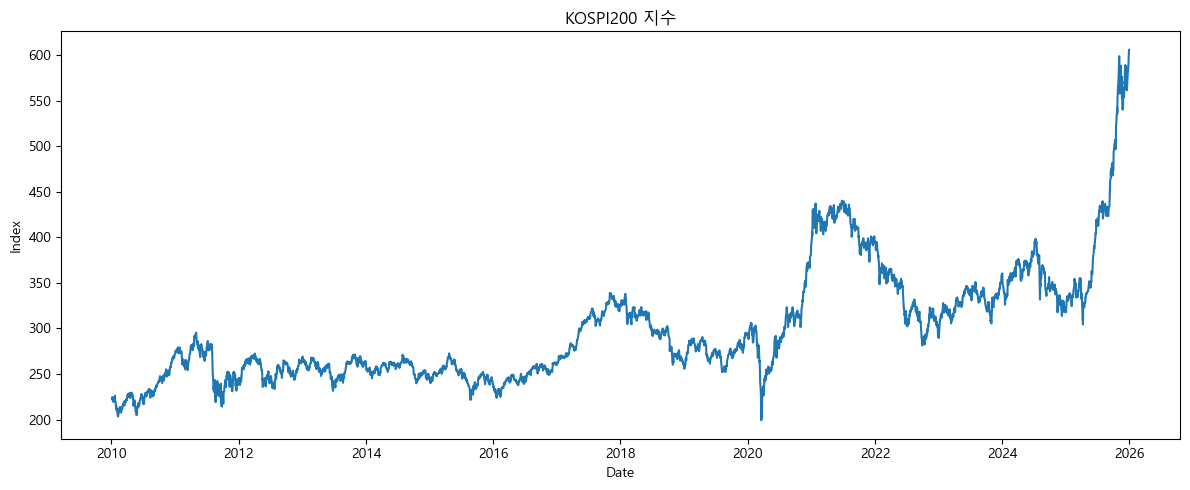

[FIGURE SAVED] outputs/figures/02_kospi200_index.png


In [19]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ks200["Date"], ks200["Close"])
ax.set_title("KOSPI200 지수")
ax.set_xlabel("Date")
ax.set_ylabel("Index")
save_figure(fig, "02_kospi200_index.png")

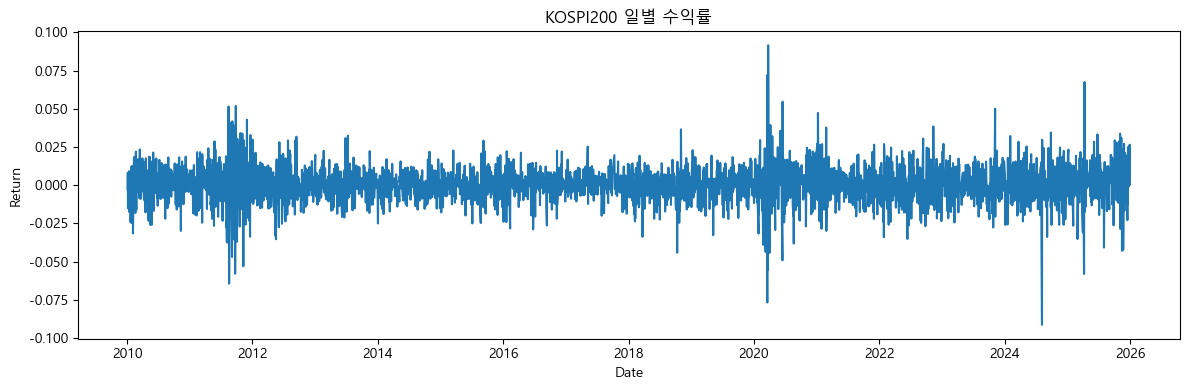

[FIGURE SAVED] outputs/figures/03_kospi200_daily_return.png


In [20]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ks200["Date"], ks200["RET"])
ax.set_title("KOSPI200 일별 수익률")
ax.set_xlabel("Date")
ax.set_ylabel("Return")
save_figure(fig, "03_kospi200_daily_return.png")

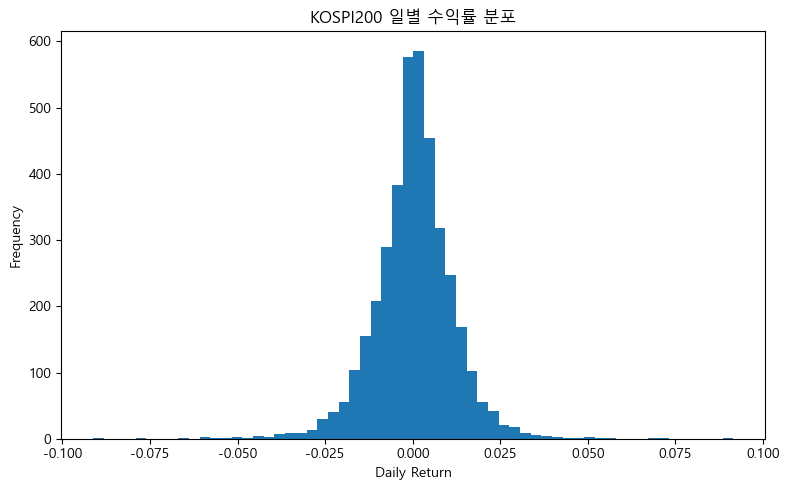

[FIGURE SAVED] outputs/figures/04_kospi200_return_distribution.png


In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(ks200["RET"].dropna(), bins=60)
ax.set_title("KOSPI200 일별 수익률 분포")
ax.set_xlabel("Daily Return")
ax.set_ylabel("Frequency")
save_figure(fig, "04_kospi200_return_distribution.png")

In [22]:
display(ks200["RET"].describe().to_frame("KOSPI200"))
print("Skewness :", ks200["RET"].skew())
print("Kurtosis :", ks200["RET"].kurt())

,KOSPI200
count,"3,938.000000"
mean,0.000318
std,0.011369
min,-0.091218
25%,-0.005554
50%,0.000503
75%,0.006435
max,0.091495


Skewness : -0.176039347166212
Kurtosis : 5.422924291856168


### 17-B. 개별 종목 EDA (전 종목)

$$
\bar R_i = \frac{1}{T_i} \sum_t R_{i,t}
$$

$$
\sigma_i = SD(R_{i,t})
$$

In [23]:
stock_summary = (
    prices.groupby(["Symbol", "Name"], dropna=False)
    .agg(
        MeanReturn=("RET", "mean"),
        Volatility=("RET", "std"),
        MinReturn=("RET", "min"),
        MaxReturn=("RET", "max"),
        AvgVolume=("Volume", "mean"),
        NPriceObs=("Close", "count"),
    )
    .reset_index()
)

display(stock_summary.sort_values("Volatility", ascending=False).head(20))

,Symbol,Name,MeanReturn,Volatility,MinReturn,MaxReturn,AvgVolume,NPriceObs
0,000080,하이트진로,0.002084,0.163573,-0.149007,13.102991,"157,185.512150",6502
14,001440,대한전선,0.005079,0.155297,-0.691074,8.047390,"613,387.949246",6502
99,032640,LG유플러스,0.005378,0.130754,-0.735759,2.834951,"1,476,162.954694",6423
77,0126Z0,삼성에피스홀딩스,0.036740,0.082924,-0.075404,0.242081,"1,362,672.880000",25
199,457190,이수스페셜티케미컬,0.002116,0.067705,-0.820324,0.300000,"440,638.131955",629
18,002030,아세아,0.001790,0.059405,-0.225806,4.073896,"3,647.082883",6479
197,450080,에코프로머티,0.001210,0.054353,-0.159551,0.299476,"1,112,987.184825",514
5,000240,한국앤컴퍼니,0.001857,0.052750,-0.250591,3.533126,"5,098,318.676561",6502
133,071970,HD현대마린엔진,-0.000370,0.045379,-0.734177,0.300000,"268,476.848182",4097
122,062040,산일전기,0.003827,0.045303,-0.128788,0.167742,"737,044.273256",344


### 17-C. 시가총액 상위 종목

,Symbol,Name,MarketCap
0,005930,삼성전자,"709,764,587.000000"
1,000660,SK하이닉스,"473,929,540.000000"
2,373220,LG에너지솔루션,"86,229,000.000000"
3,207940,삼성바이오로직스,"78,463,162.000000"
4,005380,현대차,"60,710,678.000000"
5,329180,HD현대중공업,"53,425,264.000000"
6,402340,SK스퀘어,"48,608,058.000000"
7,012450,한화에어로스페이스,"48,521,160.000000"
8,034020,두산에너빌리티,"48,234,254.000000"
9,105560,KB금융,"47,568,324.000000"


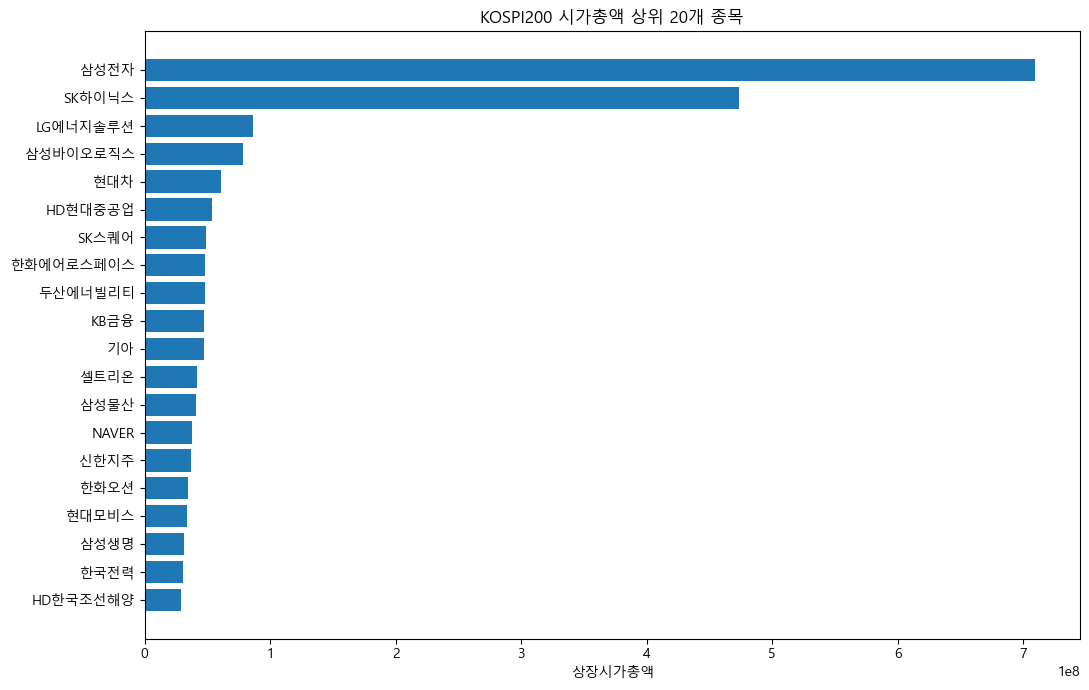

[FIGURE SAVED] outputs/figures/01_top20_marketcap.png


In [24]:
marketcap_summary = (
    universe[["Symbol", "Name", "MarketCap"]]
    .sort_values("MarketCap", ascending=False)
    .reset_index(drop=True)
)
display(marketcap_summary.head(20))

fig, ax = plt.subplots(figsize=(11, 7))
top20 = marketcap_summary.head(20).sort_values("MarketCap")
ax.barh(top20["Name"], top20["MarketCap"])
ax.set_title("KOSPI200 시가총액 상위 20개 종목")
ax.set_xlabel("상장시가총액")
save_figure(fig, "01_top20_marketcap.png")

### 17-D. 대표 종목 6개 비교 EDA

지금까지는 KOSPI200 지수 하나, 그리고 200개 전 종목을 한꺼번에 다뤘다.
이번에는 그 사이 규모 — **지수 1개 + 대표 종목 5개, 총 6개
시계열**을 나란히 놓고 비교한다.

$$
EDA\_SYMBOLS = \{005930,\ 000660,\ 005380,\ 105560,\ 068270\}
$$

(삼성전자, SK하이닉스, 현대차, KB금융, 셀트리온 — 실제로 Yahoo
데이터가 정상 다운로드되는 종목만 사용한다.)

### Failure Mode 정정: 비교할 때만 날짜를 맞춘다

개별 종목 EDA(§17-B)에서는 각 종목의 **전체 history**를 그대로
사용했다. 하지만 6개 시계열을 서로 비교(상관관계, 동일 스케일
그래프)하려면 **공통으로 겹치는 날짜만** 사용해야 한다. 두 방식을
섞으면 안 된다.

$$
\boxed{
\text{Individual EDA} \rightarrow \text{each series' own full history}
}
$$

$$
\boxed{
\text{Comparison EDA} \rightarrow \text{common overlapping dates}
}
$$

여전히 각 종목의 시작일은 서로 다르다.

$$
\boxed{
FirstPriceDate_i \neq FirstPriceDate_j
}
$$

In [25]:
EDA_SYMBOLS = ["005930", "000660", "005380", "105560", "068270"]

eda_price_frames = {}
for sym in EDA_SYMBOLS:
    sub = (
        prices[prices["Symbol"] == sym][["Date", "Close", "AdjClose", "RET"]]
        .dropna(subset=["AdjClose"])
        .sort_values("Date")
        .reset_index(drop=True)
    )
    if sub.empty:
        print(f"[WARNING] {sym} 가격자료가 없어 6-series EDA에서 제외합니다.")
        continue
    eda_price_frames[sym] = sub

EDA_SYMBOLS_AVAILABLE = list(eda_price_frames.keys())
series_label = {"KOSPI200": "KOSPI200"}
for sym in EDA_SYMBOLS_AVAILABLE:
    series_label[sym] = universe.loc[universe["Symbol"] == sym, "Name"].iloc[0]

print("EDA_SYMBOLS_AVAILABLE:", EDA_SYMBOLS_AVAILABLE)

print("\nFirstPriceDate 비교 (6개 시계열 중 개별 종목):")
display(
    coverage[coverage["Symbol"].isin(EDA_SYMBOLS_AVAILABLE)]
    [["Symbol", "Name", "FirstPriceDate", "LastPriceDate", "NPriceObs"]]
)

EDA_SYMBOLS_AVAILABLE: ['005930', '000660', '005380', '105560', '068270']

FirstPriceDate 비교 (6개 시계열 중 개별 종목):


,Symbol,Name,FirstPriceDate,LastPriceDate,NPriceObs
7,000660,SK하이닉스,2000-01-04,2025-12-30,6502
37,005380,현대차,2000-01-04,2025-12-30,6502
42,005930,삼성전자,2000-01-04,2025-12-30,6502
127,068270,셀트리온,2005-07-19,2025-12-30,5057
147,105560,KB금융,2001-12-25,2025-12-30,5987


#### 요약 통계표 (6개 시계열, 각자의 전체 history)

$$
MeanToStd_i
=
\frac{\bar R_i}{\sigma_i}
$$

이 값은 **annualized Sharpe ratio가 아니다** — 무위험이자율 차감이나
연율화 없이 단순히 평균을 표준편차로 나눈 mean-to-volatility ratio일
뿐이다.

In [26]:
def summarize_returns(name: str, ret_series: pd.Series) -> dict:
    r = ret_series.dropna()
    std = r.std()
    return {
        "Series": name,
        "Obs": int(r.count()),
        "Mean": r.mean(),
        "Std": std,
        "MeanToStd": (r.mean() / std) if std not in (0, None) and not pd.isna(std) else np.nan,
        "Skewness": r.skew(),
        "Kurtosis": r.kurt(),
        "Min": r.min(),
        "Q05": r.quantile(0.05),
        "Q50": r.quantile(0.50),
        "Q95": r.quantile(0.95),
        "Max": r.max(),
    }


eda_summary_rows = [summarize_returns("KOSPI200", ks200["RET"])]
for sym in EDA_SYMBOLS_AVAILABLE:
    eda_summary_rows.append(
        summarize_returns(series_label[sym], eda_price_frames[sym]["RET"])
    )

eda_summary_table = pd.DataFrame(eda_summary_rows)
display(eda_summary_table)

eda_summary_table.to_csv(
    TABLE_DIR / "eda_six_series_summary.csv", index=False, encoding="utf-8-sig"
)

,Series,Obs,Mean,Std,MeanToStd,Skewness,Kurtosis,Min,Q05,Q50,Q95,Max
0,KOSPI200,3938,0.000318,0.011369,0.027974,-0.176039,5.422924,-0.091218,-0.017564,0.000503,0.017521,0.091495
1,삼성전자,6501,0.000746,0.021639,0.034483,0.235905,4.916585,-0.149206,-0.031802,0.000000,0.035714,0.150001
2,SK하이닉스,6501,0.000591,0.044591,0.013254,-11.645627,515.130843,-1.904760,-0.052420,0.000000,0.057500,0.320834
3,현대차,6501,0.000829,0.025352,0.032713,0.290510,5.742940,-0.171004,-0.036304,0.000000,0.041534,0.209999
4,KB금융,5986,0.000470,0.021164,0.022190,0.639456,17.761896,-0.174020,-0.028004,0.000000,0.030725,0.243902
5,셀트리온,5056,0.001156,0.030811,0.037527,0.677574,6.331044,-0.149920,-0.042182,0.000000,0.050402,0.237838


#### Correlation Matrix (공통 구간)

6개 시계열의 일별 수익률을 **공통으로 겹치는 날짜**로 정렬한 뒤
상관관계를 계산한다.

공통 구간 관측치 수: 3933


,KOSPI200,삼성전자,SK하이닉스,현대차,KB금융,셀트리온
KOSPI200,1.000000,0.766042,0.614645,0.540352,0.555753,0.290062
삼성전자,0.766042,1.000000,0.528234,0.330329,0.309451,0.156235
SK하이닉스,0.614645,0.528234,1.000000,0.268539,0.253006,0.160213
현대차,0.540352,0.330329,0.268539,1.000000,0.297752,0.143478
KB금융,0.555753,0.309451,0.253006,0.297752,1.000000,0.141227
셀트리온,0.290062,0.156235,0.160213,0.143478,0.141227,1.000000


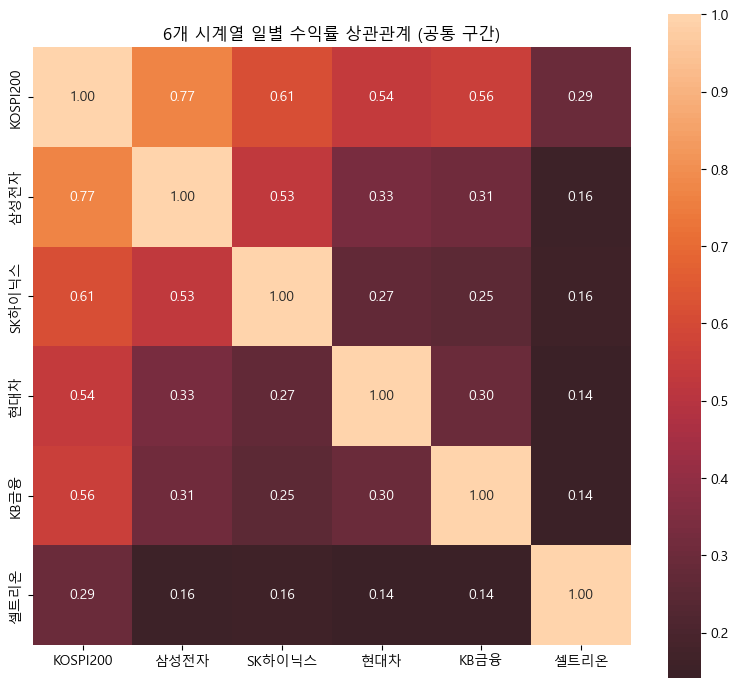

[FIGURE SAVED] outputs/figures/06_correlation_heatmap.png


In [27]:
prices_wide = ks200[["Date", "Close"]].rename(columns={"Close": "KOSPI200"})
for sym in EDA_SYMBOLS_AVAILABLE:
    sub = eda_price_frames[sym][["Date", "AdjClose"]].rename(
        columns={"AdjClose": series_label[sym]}
    )
    prices_wide = prices_wide.merge(sub, on="Date", how="inner")

prices_wide = prices_wide.sort_values("Date").reset_index(drop=True)

returns_wide = prices_wide.set_index("Date").pct_change().dropna()
corr_matrix = returns_wide.corr()

print("공통 구간 관측치 수:", len(returns_wide))
display(corr_matrix)

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", center=0, square=True, ax=ax)
ax.set_title("6개 시계열 일별 수익률 상관관계 (공통 구간)")
save_figure(fig, "06_correlation_heatmap.png")

#### 수익률 그래프 6개 — 동일 y-axis scale

각 subplot은 해당 시계열의 **전체 history**를 그대로 보여준다
(§17-B와 동일 원칙). 다만 극단값 때문에 그래프가 과도하게 압축되지
않도록, 6개 시계열 전체에서 계산한 **0.5% ~ 99.5% robust 범위**를
모든 subplot에 동일하게 적용한다.

$$
global_{q005},\ global_{q995}
$$

Common y-axis range: -0.0981535276100918 ~ 0.11925735090649077


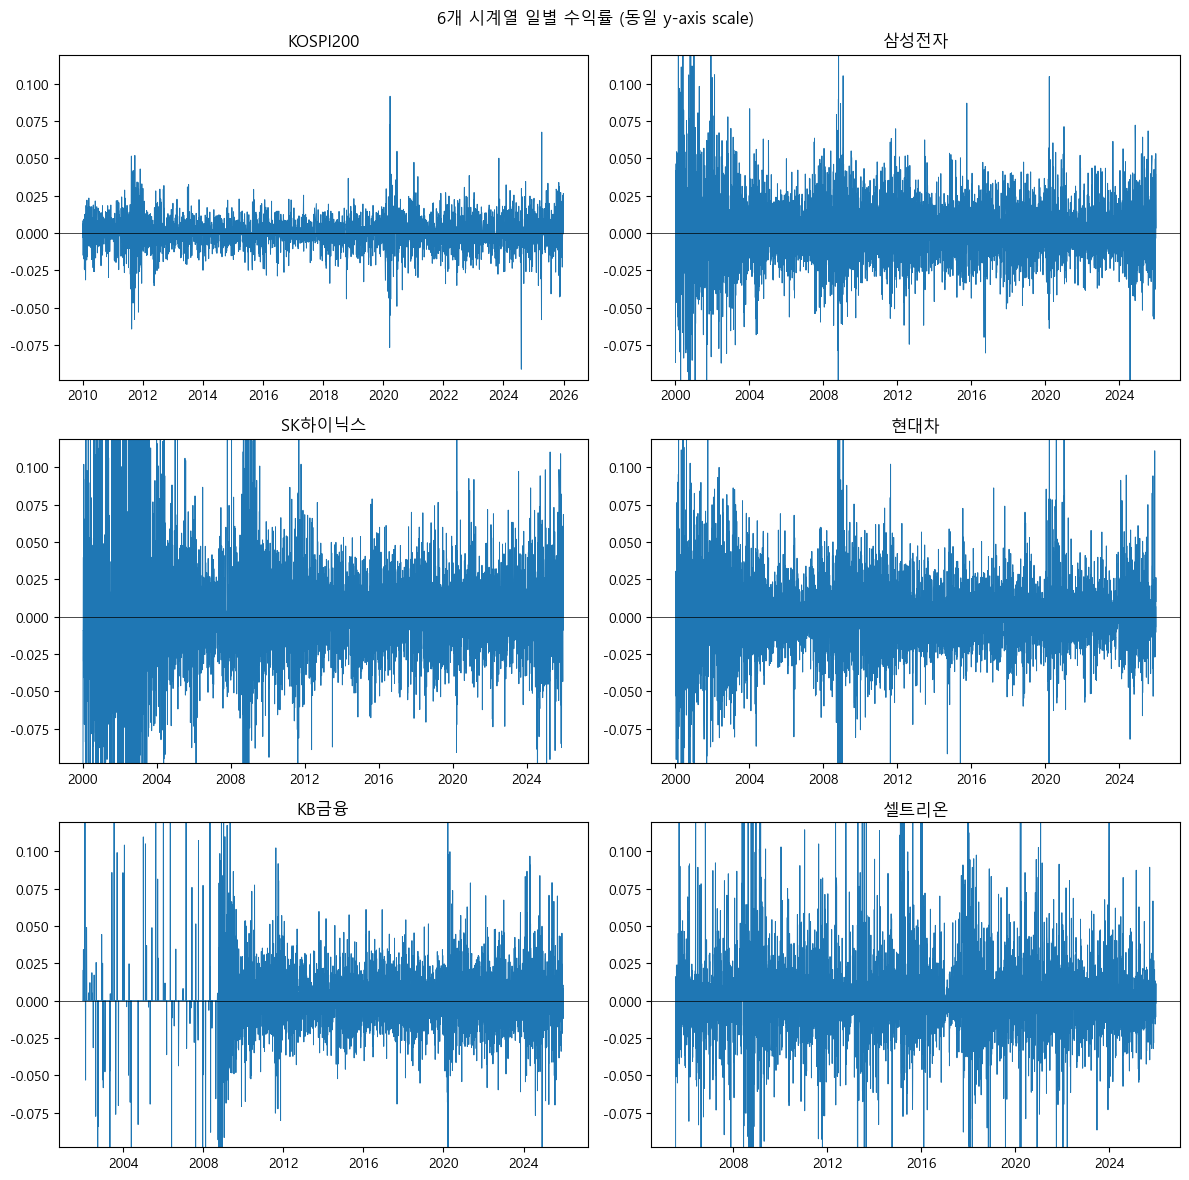

[FIGURE SAVED] outputs/figures/07_six_series_returns_same_scale.png


In [28]:
all_ret_values = pd.concat(
    [ks200["RET"]] + [eda_price_frames[sym]["RET"] for sym in EDA_SYMBOLS_AVAILABLE]
).dropna()

global_q005 = all_ret_values.quantile(0.005)
global_q995 = all_ret_values.quantile(0.995)

print("Common y-axis range:", global_q005, "~", global_q995)

plot_series = [("KOSPI200", ks200)] + [
    (series_label[sym], eda_price_frames[sym]) for sym in EDA_SYMBOLS_AVAILABLE
]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.ravel()

for ax, (name, df) in zip(axes, plot_series):
    ax.plot(df["Date"], df["RET"], linewidth=0.7)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_ylim(global_q005, global_q995)
    ax.set_title(name)

for ax in axes[len(plot_series):]:
    ax.axis("off")

fig.suptitle("6개 시계열 일별 수익률 (동일 y-axis scale)")
save_figure(fig, "07_six_series_returns_same_scale.png")

#### 가격 그래프 6개 — 독립적 y-axis + 정규화 비교

가격 수준은 종목마다 단위가 다르므로 각 subplot의 y-axis는
독립적으로 둔다. 대신 별도로 **정규화 가격 비교 chart**를 하나
추가한다 (공통 구간의 첫날을 100으로 맞춘다).

$$
NormalizedPrice_t = 100 \times \frac{P_t}{P_{first}}
$$

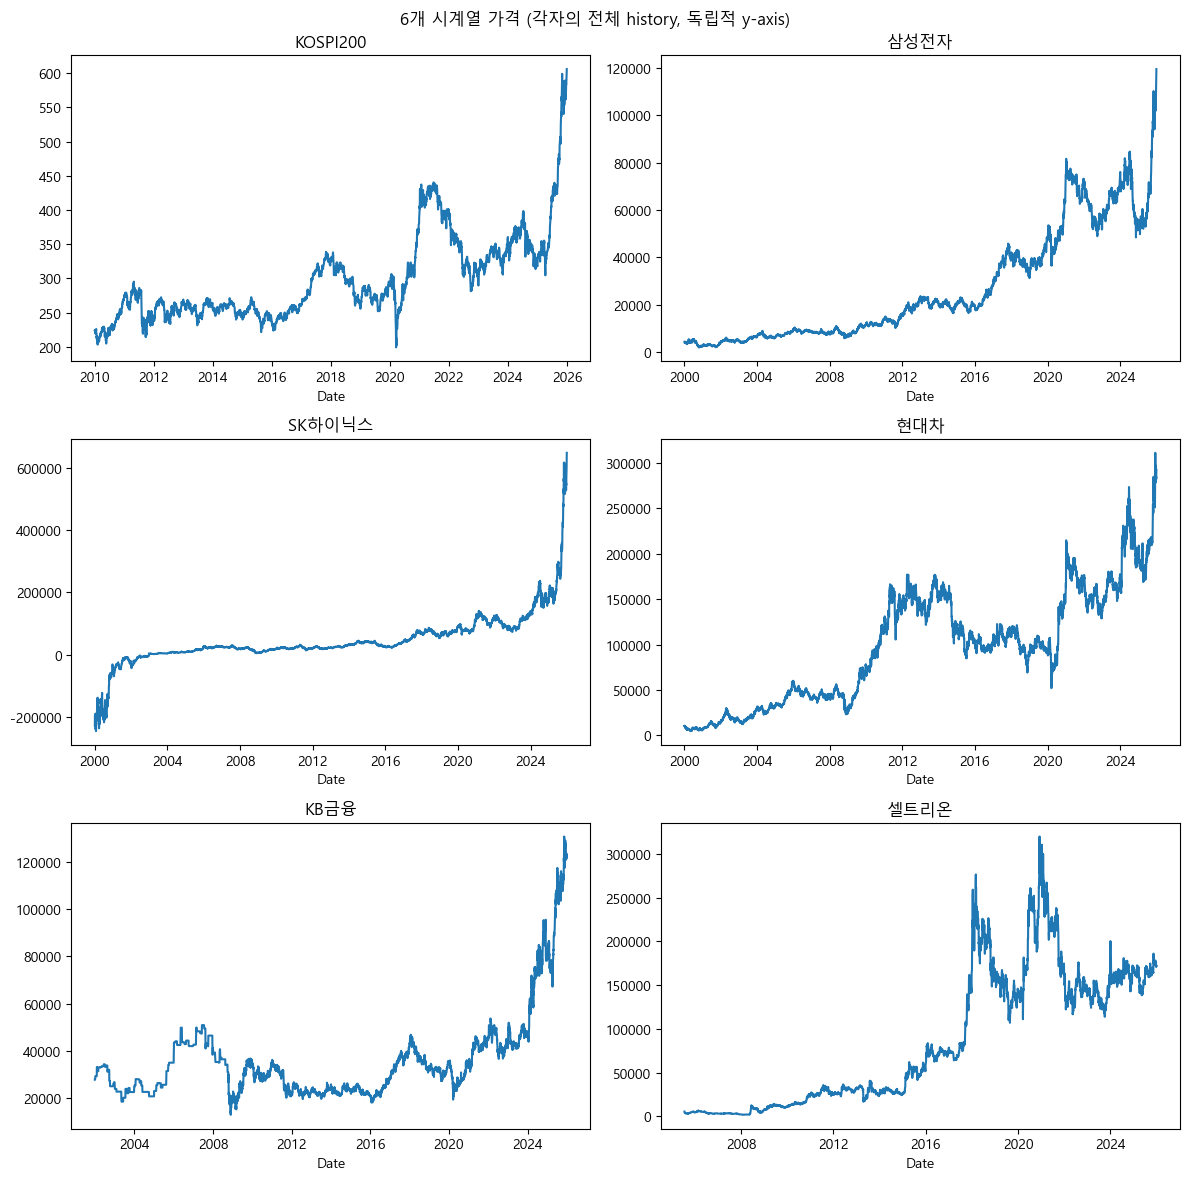

[FIGURE SAVED] outputs/figures/08_six_series_price_individual_scale.png


In [29]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.ravel()

for ax, (name, df) in zip(axes, plot_series):
    price_col = "Close" if "Close" in df.columns and name == "KOSPI200" else "AdjClose"
    ax.plot(df["Date"], df[price_col])
    ax.set_title(name)
    ax.set_xlabel("Date")

for ax in axes[len(plot_series):]:
    ax.axis("off")

fig.suptitle("6개 시계열 가격 (각자의 전체 history, 독립적 y-axis)")
save_figure(fig, "08_six_series_price_individual_scale.png")

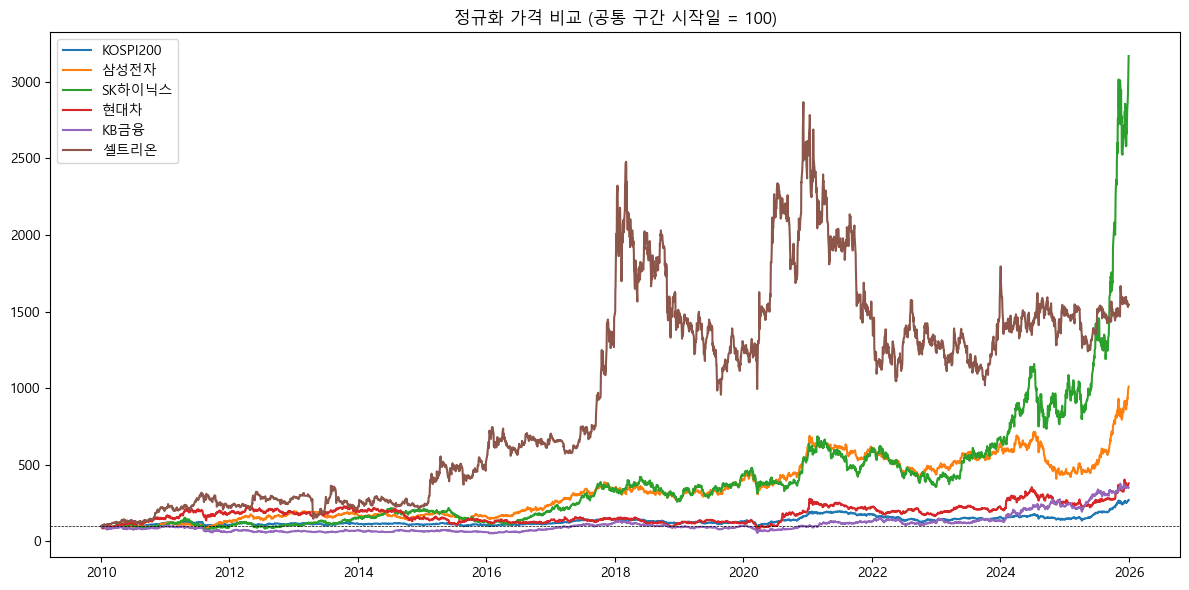

[FIGURE SAVED] outputs/figures/09_normalized_price_comparison.png


In [30]:
normalized_prices = prices_wide.copy()
base_row = normalized_prices.iloc[0]
for col in normalized_prices.columns:
    if col == "Date":
        continue
    normalized_prices[col] = 100 * normalized_prices[col] / base_row[col]

fig, ax = plt.subplots(figsize=(12, 6))
for col in normalized_prices.columns:
    if col == "Date":
        continue
    ax.plot(normalized_prices["Date"], normalized_prices[col], label=col)
ax.axhline(100, color="black", linewidth=0.5, linestyle="--")
ax.legend()
ax.set_title("정규화 가격 비교 (공통 구간 시작일 = 100)")
save_figure(fig, "09_normalized_price_comparison.png")

### 17-E. 대표 종목: 삼성전자 (005930)

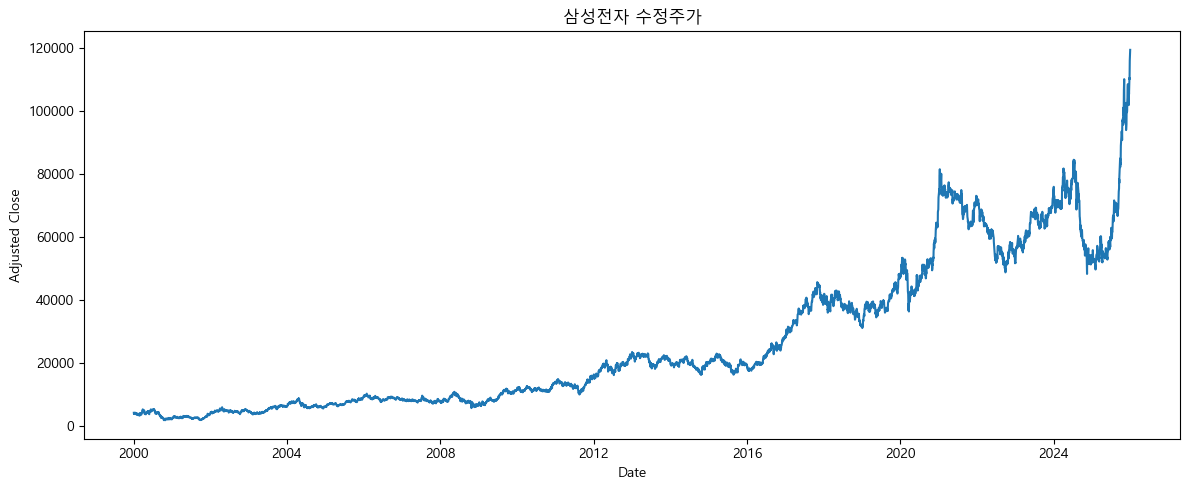

[FIGURE SAVED] outputs/figures/05_example_stock_price.png


In [31]:
EXAMPLE_SYMBOL = "005930"
example = prices[prices["Symbol"] == EXAMPLE_SYMBOL].copy()

if not example.empty:
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(example["Date"], example["AdjClose"])
    example_name = example["Name"].iloc[0]
    ax.set_title(f"{example_name} 수정주가")
    ax.set_xlabel("Date")
    ax.set_ylabel("Adjusted Close")
    save_figure(fig, "05_example_stock_price.png")

### 17-F. 산업별 EDA (helper example)

산업분류가 있으면 산업 $j$의 일별 동일가중 수익률:

$$
R_{j,t} = \frac{1}{N_{j,t}} \sum_{i \in j} R_{i,t}
$$

이 셀은 **Assignment 1에서 그대로 재사용할 수 있는 helper
example**이다. 지금은 `universe["Industry"]`가 비어 있으므로
아래 셀은 건너뛴 메시지를 출력한다.

In [32]:
if universe["Industry"].notna().any():
    industry_daily = (
        prices.dropna(subset=["RET", "Industry"])
        .groupby(["Date", "Industry"])
        .agg(IndustryRET=("RET", "mean"), NStocks=("Symbol", "nunique"))
        .reset_index()
    )
    industry_summary = (
        industry_daily.groupby("Industry")
        .agg(
            MeanReturn=("IndustryRET", "mean"),
            Volatility=("IndustryRET", "std"),
            AvgNStocks=("NStocks", "mean"),
        )
        .reset_index()
    )
    display(industry_summary)
else:
    industry_daily = None
    industry_summary = None
    print("[SKIP] 산업분류가 아직 결합되지 않아 산업별 분석을 건너뜁니다.")

[SKIP] 산업분류가 아직 결합되지 않아 산업별 분석을 건너뜁니다.


## 18. Survivorship Bias — 구성종목은 시간에 따라 바뀐다

### Concept

현재(2025-12-30) 구성종목과 과거 어느 시점의 구성종목은 같지 않다.

$$
C_t \neq C_{2025}
$$

$$
\boxed{
\text{Longer price history does NOT imply point-in-time correct universe.}
}
$$

`period="max"`로 가격 history를 길게 받는 것과, universe가
point-in-time으로 정확한 것은 전혀 다른 문제다.

### Formula

historical membership data에는 보통 하나의 시점이 아니라 여러
시점 $t = 1, 2, \ldots, T$ 의 스냅샷이 들어 있다. 각 시점의
구성종목 집합을 $C_t$ 라고 하면, 연속된 두 시점 사이의 변화는
다음과 같이 정의한다.

$$
Stayed_t = C_t \cap C_{t-1}
$$

$$
Added_t = C_t - C_{t-1}
$$

$$
Deleted_t = C_{t-1} - C_t
$$

$$
Turnover_t
=
\frac{|Added_t| + |Deleted_t|}{2|C_{t-1}|}
$$

두 시점만 골라 한 번 비교하는 것으로는 부족하다 — **historical
membership data가 존재하는 전체 기간**에 대해 이 값들을 시계열로
계산해야 실제 구성종목의 변화 과정을 볼 수 있다. 이것이
**Assignment 2의 핵심**이다.

`compare_constituents()`는 두 시점(예: $C_{t-1}$, $C_t$)의 집합을
받아 Stayed/Added/Deleted/SurvivalRate를 계산해 주는 helper이다.
전체 기간을 다룰 때는 이 함수를 매 시점 쌍 $(C_{t-1}, C_t)$ 마다
반복 호출한다.

In [33]:
def compare_constituents(old_symbols, new_symbols):
    old_set = set(pd.Series(old_symbols).dropna().astype(str).str.zfill(6))
    new_set = set(pd.Series(new_symbols).dropna().astype(str).str.zfill(6))

    stayed = old_set & new_set
    added = new_set - old_set
    deleted = old_set - new_set
    survival_rate = len(stayed) / len(old_set) if old_set else np.nan

    return {
        "Stayed": stayed,
        "Added": added,
        "Deleted": deleted,
        "SurvivalRate": survival_rate,
    }

## 19. Lab 1 데이터 저장

Lab 2/3는 Yahoo/FDR을 다시 호출하지 않고 이번에 저장한 데이터를
재사용한다.

In [34]:
universe_output = DATA_DIR / f"kospi200_universe_{ASOF_DATE:%Y%m%d}.parquet"
prices_output = DATA_DIR / f"kospi200_prices_max_to_{ASOF_DATE:%Y%m%d}.parquet"
index_output = DATA_DIR / f"kospi200_index_max_to_{ASOF_DATE:%Y%m%d}.parquet"

coverage_output = TABLE_DIR / "kospi200_price_coverage.csv"
stock_summary_output = TABLE_DIR / "kospi200_stock_summary.csv"
failed_output = TABLE_DIR / "yahoo_failed_tickers.csv"
extreme_returns_output = TABLE_DIR / "extreme_returns_diagnostic.csv"

universe.to_parquet(universe_output, index=False)
prices.to_parquet(prices_output, index=False)
ks200.to_parquet(index_output, index=False)

coverage.to_csv(coverage_output, index=False, encoding="utf-8-sig")
stock_summary.to_csv(stock_summary_output, index=False, encoding="utf-8-sig")
extreme_returns.to_csv(extreme_returns_output, index=False, encoding="utf-8-sig")
pd.DataFrame({"YahooTicker": failed_tickers}).to_csv(
    failed_output, index=False, encoding="utf-8-sig"
)

if industry_summary is not None:
    industry_summary.to_csv(
        TABLE_DIR / "kospi200_industry_summary.csv", index=False, encoding="utf-8-sig"
    )

print("\n========================================")
print("LAB 1 OUTPUTS SAVED")
print("========================================")
for p in [universe_output, prices_output, index_output, coverage_output,
          stock_summary_output, failed_output, extreme_returns_output]:
    print(p.as_posix())


LAB 1 OUTPUTS SAVED
data/kospi200_universe_20251230.parquet
data/kospi200_prices_max_to_20251230.parquet
data/kospi200_index_max_to_20251230.parquet
outputs/tables/kospi200_price_coverage.csv
outputs/tables/kospi200_stock_summary.csv
outputs/tables/yahoo_failed_tickers.csv
outputs/tables/extreme_returns_diagnostic.csv


# Assignment 1
## KOSPI200 구성종목과 산업구조 분석

### 목표

현재 KOSPI200 구성종목을 확인하고, 각 종목의 산업분류를 찾아
KOSPI200의 산업구조를 분석한다.

### 여러분이 직접 준비할 데이터

- KOSPI200 구성종목
- 구성종목의 산업분류
- 분석에 필요한 주가자료

산업분류는 스스로 선택한 신뢰할 수 있는 자료를 사용할 수 있다
(예: 거래소 업종, KSIC, 기타 신뢰할 수 있는 산업분류). 단, **어떤
산업분류를 사용했는지 반드시 명시**한다 (Notebook 뒷부분의 "데이터
출처 기록" 표에 적는다).

### 필요한 계산

$$
Share_{j,t}
=
\frac{N_{j,t}}{N_t}
$$

$$
R_{j,t} = \frac{1}{N_{j,t}} \sum_{i \in j} R_{i,t}
$$

### 할 일

- 산업별 종목 수 계산
- 산업별 구성비 계산
- 산업별 평균수익률 계산
- 산업별 변동성 계산
- 결과 표 작성
- 그래프 최소 1개 작성
- 결과 3~5문장 해석

### 참고

자신이 준비한 산업분류 파일을 아래처럼 상대경로로 불러오고, 이
`universe`에 `Symbol` 기준으로 결합하면 된다.

```python
my_industry = pd.read_csv(Path("data/FDA_kospi200_industry.csv"))
universe = universe.merge(my_industry, on="Symbol", how="left")
```

위 파일명은 예시다. 본인이 정리한 파일명을 그대로 사용해도 된다.

산업분류 매칭: 200 / 200 (미매칭 0)

N = 200


,Industry,NStocks,MarketCap,Share,MarketCapShare
0,화학,34,"125,622,455",17.0%,4.0%
1,기타금융,30,"381,460,963",15.0%,12.1%
2,전기·전자,21,"1,452,034,137",10.5%,46.0%
3,유통,13,"73,313,034",6.5%,2.3%
4,운송장비·부품,12,"338,533,579",6.0%,10.7%
5,일반서비스,10,"43,786,800",5.0%,1.4%
6,음식료·담배,10,"41,902,150",5.0%,1.3%
7,제약,10,"147,390,899",5.0%,4.7%
8,IT 서비스,9,"114,252,186",4.5%,3.6%
9,금속,9,"71,647,195",4.5%,2.3%


,Industry,NStocks,Share,MarketCapShare,MeanDaily,StdDaily,MeanAnnual,VolAnnual,MeanToVol
0,화학,34,17.0%,4.0%,0.0781%,1.56%,19.7%,24.7%,0.80
1,기타금융,30,15.0%,12.1%,0.0931%,1.50%,23.5%,23.8%,0.99
2,전기·전자,21,10.5%,46.0%,0.1136%,2.08%,28.6%,33.0%,0.87
3,유통,13,6.5%,2.3%,0.0763%,1.54%,19.2%,24.4%,0.79
4,운송장비·부품,12,6.0%,10.7%,0.0941%,1.87%,23.7%,29.7%,0.80
5,일반서비스,10,5.0%,1.4%,0.0897%,1.68%,22.6%,26.7%,0.85
6,음식료·담배,10,5.0%,1.3%,0.0915%,2.41%,23.1%,38.2%,0.60
7,제약,10,5.0%,4.7%,0.0998%,1.89%,25.2%,29.9%,0.84
8,IT 서비스,9,4.5%,3.6%,0.0707%,2.47%,17.8%,39.1%,0.45
9,금속,9,4.5%,2.3%,0.0876%,1.87%,22.1%,29.7%,0.74


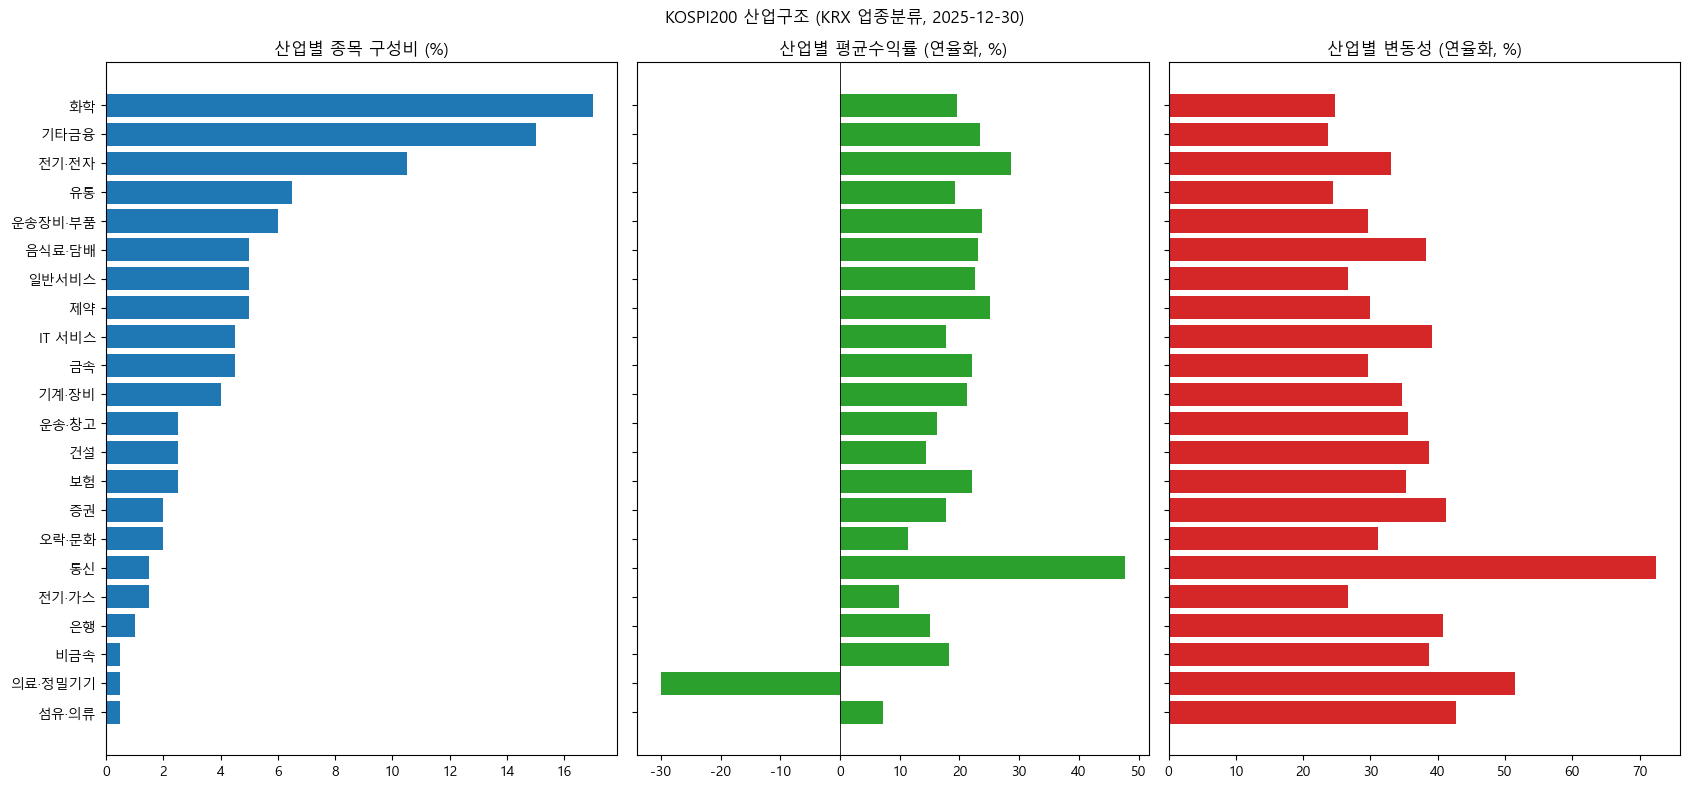

[FIGURE SAVED] outputs/figures/10_assignment1_industry_structure.png


In [35]:
# ============================================================
# Assignment 1 — Student Work
# ============================================================
# 산업분류: KRX 정보데이터시스템 > 업종분류현황 (기준일 2025-12-30)
# 원본 파일: data/data_1628_20261003.csv  (KOSPI 전 종목의 KRX 업종명 포함)

# ------------------------------------------------------------
# 1) 산업분류 파일 정리 → data/ 에 저장 → universe에 결합
# ------------------------------------------------------------
# KRX_INDUSTRY_RAW 경로는 Configuration 셀에서 정의 (data/ 아래)
krx_raw = pd.read_csv(KRX_INDUSTRY_RAW, encoding="cp949", dtype={"종목코드": str})
my_industry = (
    krx_raw.rename(columns={"종목코드": "Symbol", "업종명": "Industry"})
    [["Symbol", "Industry"]]
    .assign(Symbol=lambda d: normalize_symbol(d["Symbol"]))
    .drop_duplicates(subset="Symbol")
)
my_industry.to_csv(DATA_DIR / "FDA_kospi200_industry.csv", index=False, encoding="utf-8-sig")

my_industry = pd.read_csv(Path("data/FDA_kospi200_industry.csv"), dtype={"Symbol": str})

# Lab에서 비워둔 Industry 컬럼을 제거한 뒤 Symbol 기준으로 결합
universe = universe.drop(columns=["Industry"], errors="ignore").merge(
    my_industry, on="Symbol", how="left"
)

n_missing = universe["Industry"].isna().sum()
print(f"산업분류 매칭: {universe['Industry'].notna().sum()} / {len(universe)} (미매칭 {n_missing})")
if n_missing:
    display(universe.loc[universe["Industry"].isna(), ["Symbol", "Name"]])

# prices에도 산업분류 반영 (Lab에서 만든 prices의 Industry는 NaN)
prices = prices.drop(columns=["Industry"], errors="ignore").merge(
    universe[["Symbol", "Industry"]], on="Symbol", how="left"
)

# ------------------------------------------------------------
# 2) 산업별 종목 수, 구성비:  Share_j = N_j / N
# ------------------------------------------------------------
N_total = universe["Symbol"].nunique()
industry_count = (
    universe.dropna(subset=["Industry"])
    .groupby("Industry")
    .agg(NStocks=("Symbol", "nunique"), MarketCap=("MarketCap", "sum"))
    .reset_index()
)
industry_count["Share"] = industry_count["NStocks"] / N_total
industry_count["MarketCapShare"] = industry_count["MarketCap"] / universe["MarketCap"].sum()
industry_count = industry_count.sort_values("NStocks", ascending=False).reset_index(drop=True)

print(f"\nN = {N_total}")
display(industry_count.style.format({"Share": "{:.1%}", "MarketCapShare": "{:.1%}", "MarketCap": "{:,.0f}"}))

# ------------------------------------------------------------
# 3) 산업별 평균수익률 / 변동성 (동일가중 일별 수익률 R_{j,t})
# ------------------------------------------------------------
industry_daily = (
    prices.dropna(subset=["RET", "Industry"])
    .groupby(["Date", "Industry"])
    .agg(IndustryRET=("RET", "mean"), NStocks_t=("Symbol", "nunique"))
    .reset_index()
)

TRADING_DAYS = 252
industry_ret = (
    industry_daily.groupby("Industry")
    .agg(
        MeanDaily=("IndustryRET", "mean"),
        StdDaily=("IndustryRET", "std"),
        AvgNStocks=("NStocks_t", "mean"),
        Days=("IndustryRET", "count"),
    )
    .reset_index()
)
industry_ret["MeanAnnual"] = industry_ret["MeanDaily"] * TRADING_DAYS
industry_ret["VolAnnual"] = industry_ret["StdDaily"] * np.sqrt(TRADING_DAYS)
industry_ret["MeanToVol"] = industry_ret["MeanAnnual"] / industry_ret["VolAnnual"]

# ------------------------------------------------------------
# 4) 결과 표
# ------------------------------------------------------------
assignment1_table = (
    industry_count[["Industry", "NStocks", "Share", "MarketCapShare"]]
    .merge(industry_ret[["Industry", "MeanDaily", "StdDaily", "MeanAnnual", "VolAnnual", "MeanToVol"]],
           on="Industry", how="left")
    .sort_values("NStocks", ascending=False)
    .reset_index(drop=True)
)
display(assignment1_table.style.format({
    "Share": "{:.1%}", "MarketCapShare": "{:.1%}",
    "MeanDaily": "{:.4%}", "StdDaily": "{:.2%}",
    "MeanAnnual": "{:.1%}", "VolAnnual": "{:.1%}", "MeanToVol": "{:.2f}",
}))
assignment1_table.to_csv(TABLE_DIR / "assignment1_industry_table.csv", index=False, encoding="utf-8-sig")

# ------------------------------------------------------------
# 5) 그래프: 구성비 / 연율화 평균수익률 / 연율화 변동성
# ------------------------------------------------------------
plot_df = assignment1_table.sort_values("NStocks")
fig, axes = plt.subplots(1, 3, figsize=(17, 8), sharey=True)

axes[0].barh(plot_df["Industry"], plot_df["Share"] * 100)
axes[0].set_title("산업별 종목 구성비 (%)")

axes[1].barh(plot_df["Industry"], plot_df["MeanAnnual"] * 100, color="tab:green")
axes[1].axvline(0, color="black", linewidth=0.6)
axes[1].set_title("산업별 평균수익률 (연율화, %)")

axes[2].barh(plot_df["Industry"], plot_df["VolAnnual"] * 100, color="tab:red")
axes[2].set_title("산업별 변동성 (연율화, %)")

fig.suptitle("KOSPI200 산업구조 (KRX 업종분류, 2025-12-30)")
fig.tight_layout()
save_figure(fig, "10_assignment1_industry_structure.png")
plt.show()


### Assignment 1 Interpretation

분석 결과를 3~5문장으로 해석하시오.

종목 수 기준으로는 화학(34개, 17.0%)과 기타금융(30개, 15.0%)이 가장 많지만, 시가총액 기준으로는 전기·전자가 21개(10.5%)에 불과함에도 46.0%를 차지해, KOSPI200은 종목 수로 보면 분산되어 있어도 실제 가치 비중은 삼성전자·SK하이닉스 중심의 반도체 업종에 크게 집중되어 있습니다. 동일가중 일별 수익률을 연율화하면 전기·전자(평균 28.6%, 변동성 33.0%)와 제약(25.2%, 29.9%)의 수익률이 높았고, 기타금융은 평균 23.5%에 변동성 23.8%로 평균/변동성 비율(0.99)이 가장 높았던 반면, 건설(14.5%, 38.8%)·증권(17.7%, 41.3%)·은행(15.1%, 40.8%)은 수익률에 비해 변동성이 커 위험 대비 성과가 낮았다. 다만 통신(평균 47.8%, 변동성 72.4%)과 음식료·담배(변동성 38.2%)의 높은 수치는 LG유플러스·하이트진로 등에서 나타난 Yahoo 데이터의 극단 수익률(§16)에 크게 영향을 받은 것으로 보이며, 종목이 1~3개뿐인 산업(통신, 은행, 섬유·의류, 의료·정밀기기 등)은 개별 종목 이벤트가 곧 산업 수익률이 되므로 해석에 주의해야 합니다. 또한 이 수익률은 2025-12-30 현재 구성종목의 전체 가격 history로 계산했기 때문에, 과거에 편출되거나 상장폐지된 종목이 빠진 survivorship bias가 포함되어 실제보다 높게 추정되었을 가능성이 큽니다. 

In [36]:
# ============================================================
# Assignment 1 — 결과 요약
# ============================================================
# 평균수익률·변동성: 산업별 동일가중 "일별" 수익률 R_{j,t}의 평균 / 표준편차
# (연율화 값은 위 결과표의 MeanAnnual, VolAnnual 참고)
a1_largest  = industry_count.loc[industry_count["NStocks"].idxmax()]
a1_best_ret = industry_ret.loc[industry_ret["MeanDaily"].idxmax()]
a1_best_vol = industry_ret.loc[industry_ret["StdDaily"].idxmax()]

print("[RESULT] A1_N_STOCKS =", N_total)
print("[RESULT] A1_N_INDUSTRIES =", industry_count["Industry"].nunique())

print("[RESULT] A1_LARGEST_INDUSTRY =", a1_largest["Industry"])
print("[RESULT] A1_LARGEST_INDUSTRY_SHARE =", float(a1_largest["Share"]))

print("[RESULT] A1_HIGHEST_RETURN_INDUSTRY =", a1_best_ret["Industry"])
print("[RESULT] A1_HIGHEST_MEAN_RETURN =", float(a1_best_ret["MeanDaily"]))

print("[RESULT] A1_HIGHEST_VOLATILITY_INDUSTRY =", a1_best_vol["Industry"])
print("[RESULT] A1_HIGHEST_VOLATILITY =", float(a1_best_vol["StdDaily"]))


[RESULT] A1_N_STOCKS = 200
[RESULT] A1_N_INDUSTRIES = 22
[RESULT] A1_LARGEST_INDUSTRY = 화학
[RESULT] A1_LARGEST_INDUSTRY_SHARE = 0.17
[RESULT] A1_HIGHEST_RETURN_INDUSTRY = 통신
[RESULT] A1_HIGHEST_MEAN_RETURN = 0.0018968636782261922
[RESULT] A1_HIGHEST_VOLATILITY_INDUSTRY = 통신
[RESULT] A1_HIGHEST_VOLATILITY = 0.045606360332132626


# Assignment 2
## KOSPI200 구성종목 변화와 Survivorship Bias

### 목표

historical constituent data가 존재하는 **전체 기간**에 대해
KOSPI200 구성종목의 변화 과정을 분석한다. 두 시점만 골라 한 번
비교하는 것으로는 이 Assignment를 완성한 것으로 보지 않는다.

### 여러분이 직접 준비할 데이터

가능한 긴 기간의 KOSPI200 historical constituent data. 각
observation/snapshot의 기준일(`AsOfDate`)이 명확해야 한다. (가능하면
산업분류도 함께 포함되어 있으면 좋다 — 없으면 Assignment 1에서
준비한 산업분류를 재사용해도 된다.)

### 필요한 계산

시점 $t = 1, 2, \ldots, T$ 각각의 구성종목 집합을 $C_t$ 라고 하면
(Lab § 18 참고):

$$
Stayed_t = C_t \cap C_{t-1}
$$

$$
Added_t = C_t - C_{t-1}
$$

$$
Deleted_t = C_{t-1} - C_t
$$

$$
Turnover_t
=
\frac{|Added_t| + |Deleted_t|}{2|C_{t-1}|}
$$

장기 요약 지표로, 가장 이른 시점 $C_1$ 과 가장 늦은 시점 $C_T$
사이의 survival rate도 계산한다.

$$
SurvivalRate_{1,T}
=
\frac{|C_1 \cap C_T|}{|C_1|}
$$

그리고 historical sample 전체에서 한 번이라도 KOSPI200에 포함된
distinct 종목 수:

$$
N^{ever}
=
\left|
\bigcup_{t=1}^{T} C_t
\right|
$$

### 할 일

1. 데이터에 존재하는 모든 구성종목 기준일 확인
2. 각 시점의 구성종목 집합 $C_t$ 생성
3. 모든 연속 시점에서 $Added_t$ 계산
4. 모든 연속 시점에서 $Deleted_t$ 계산
5. 모든 연속 시점에서 $Stayed_t$ 계산
6. turnover time series 계산
7. 변화과정 table 작성
8. turnover 또는 Added/Deleted graph 작성
9. 전체 기간 편입/편출 종목의 산업분포 분석
10. 최초-최종 장기 survival rate 계산 ($SurvivalRate_{1,T}$)
11. historical period 전체의 distinct member 수 계산 ($N^{ever}$)
12. 3~5문장 survivorship-bias 해석

### Required Output

**Table 1 — historical membership-change table**: 컬럼
`Date, N_Constituents, N_Stayed, N_Added, N_Deleted, Turnover`

**Table 2 — 편입/편출 종목의 산업분포** (전체 기간 누적)

**Graph**: turnover time series, 또는 Added/Deleted time series

**Summary**: `FirstDate, LastDate, N_Snapshots, N_Ever_Members,
LongRun_SurvivalRate`

**Interpretation**: 3~5문장

해석에서는 다음을 생각해본다.

- KOSPI200 constituent turnover는 시간에 따라 일정한가?
- 편입과 편출이 많았던 시기는 언제인가?
- 어떤 산업에서 편입/편출이 많이 발생했는가?
- 최초 constituent 중 마지막까지 남아 있는 비율은 얼마인가?
- historical period 전체에서 한 번이라도 KOSPI200에 포함된 기업 수는
  현재 구성종목 수와 얼마나 다른가?
- 현재 구성종목만 사용해 과거를 분석하면 어떤 기업들이 체계적으로
  빠지는가?
- 이러한 누락이 과거 수익률이나 기술적 전략 평가를 어떻게 왜곡할 수
  있는가?

### 핵심 논리

현재 universe $C_T$ 와 과거 어느 시점의 universe $C_t$ 는 일반적으로
같지 않다.

$$
C_t \neq C_T
$$

그리고 전체 기간 동안 KOSPI200을 거쳐간 종목의 합집합은 현재
구성종목 집합보다 훨씬 넓을 수 있다.

$$
\boxed{
\text{Current-Universe Backtest} \neq \text{Point-in-Time Universe Backtest}
}
$$

$$
\boxed{
\text{Long Price History} \neq \text{Historical Membership History}
}
$$

### 참고

`Turnover_t`의 분모를 `2|C_{t-1}|`로 둔 것은 하나의 관례(convention)
일 뿐이다 — 본인이 사용한 historical dataset의 구성이 다르다면 다른
convention(예: `|C_{t-1} \cup C_t|`)을 쓸 수도 있다. **어떤 convention을
사용했는지 코드 주석이나 해석에 명시**한다.

```python
history = pd.read_csv(Path("data/FDA_kospi200_constituents_history.csv"))
history["AsOfDate"] = pd.to_datetime(history["AsOfDate"])
```

위 파일명은 예시다. 본인이 준비한 파일명을 그대로 사용해도 된다.

Snapshot files: 40
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[PASS] CSV encoding = cp949
[

,Date,N_Constituents,N_Stayed,N_Added,N_Deleted,Turnover
0,2006-12-28 00:00:00,200,200,0,0,0.00%
1,2007-08-31 00:00:00,200,188,12,12,6.00%
2,2007-12-28 00:00:00,200,198,2,2,1.00%
3,2008-08-29 00:00:00,200,185,15,15,7.50%
4,2008-12-30 00:00:00,200,199,1,1,0.50%
5,2009-08-31 00:00:00,200,184,16,16,8.00%
6,2009-12-30 00:00:00,200,200,0,0,0.00%
7,2010-08-31 00:00:00,200,189,11,11,5.50%
8,2010-12-30 00:00:00,200,199,1,1,0.50%
9,2011-08-31 00:00:00,200,178,22,22,11.00%



시점별 편입/편출 종목 (Stayed 종목 수는 위 Table 1의 N_Stayed)


Change,Added,Deleted
Date,,
2007-08-31,"VGX인터, 대한화섬, 동화약품, 미래에셋증권, 베이직하우스, 삼성E&A, 세하, 일성신약, 조선내화, 한국카본, 한미반도체, 환인제약","LG카드, 동부일렉트로닉스, 디피아이홀딩스, 세종공업, 이수화학, 코리아써키트, 코오롱유화, 팬택, 팬택앤큐리텔, 퍼스텍, 한독약품, 한솔홈데코"
2007-12-28,"LG, SK이노베이션","KEC홀딩스, LG석유화학"
2008-08-29,"BNG스틸, KC코트렐, KPX화인케미칼, LF, STX, 경방, 대경기계, 대한제강, 세원셀론텍, 아모레퍼시픽, 유니드, 인디에프, 케이씨오에너지, 한국기술산업, 후성","S&TC, VGX인터, 대원강업, 대한화섬, 미래산업, 삼양식품, 삼진제약, 아이에스동서, 에스엘, 오리엔트바이오, 이엔페이퍼, 자화전자, 트라이브랜즈, 포항강판, 환인제약"
2008-12-30,KB금융,국민은행
2009-08-31,"CJ대한통운, CJ제일제당, DN오토모티브, NAVER, 대한제당, 모토닉, 무림P&P, 삼광글라스, 삼성카드, 삼진제약, 세방전지, 엔케이, 팬오션, 포스코플랜텍, 한독약품, 한진중공업","BNG스틸, FnC코오롱, KG모빌리티, KTF, 동원F&B, 베이직하우스, 성신양회, 셀런, 일진홀딩스, 케이씨텍, 코리안리, 크라운제과, 풍산홀딩스, 한국유리, 한미반도체, 현대오토넷"
2010-08-31,"LG유플러스, LG이노텍, LX하우시스, S&TC, 송원산업, 알앤엘바이오, 일진전기, 풍산, 하이트맥주, 한국철강, 현대글로비스","AK홀딩스, KC코트렐, 금호산업, 금호타이어, 동양기전, 세하, 신성홀딩스, 인디에프, 케이씨오에너지, 한국기술산업, 한일현대시멘트"
2010-12-30,삼성생명,영진약품
2011-08-31,"BNK금융지주, HD현대마린엔진, KG모빌리티, SK, 광전자, 국도화학, 금호타이어, 동아원, 동양기전, 락앤락, 베이직하우스, 서연, 세종공업, 아이에스동서, 에스엘, 일진디스플, 코오롱인더, 하이트진로, 한국쉘석유, 한전기술, 한화생명, 화신","JW중외제약, KISCO홀딩스, S&TC, 광동제약, 대경기계, 대구은행, 대한제당, 동원시스템즈, 동화약품, 무림페이퍼, 부산은행, 삼양제넥스, 삼진제약, 세원셀론텍, 엔케이, 일동홀딩스, 전기초자, 하이트맥주, 한국제지, 한국카본, 한독약품, 한미사이언스"
2012-08-31,"대원강업, 롯데에너지머티리얼즈, 무학, 웅진에너지, 이수화학, 파미셀, 한라홀딩스, 한미약품, 한올바이오파마, 한화엔진, 현대위아","HD현대마린엔진, KPX화인케미칼, 광전자, 금호전기, 대덕GDS, 대한제강, 삼영전자, 아세아, 유니온스틸, 율촌화학, 퍼시스"


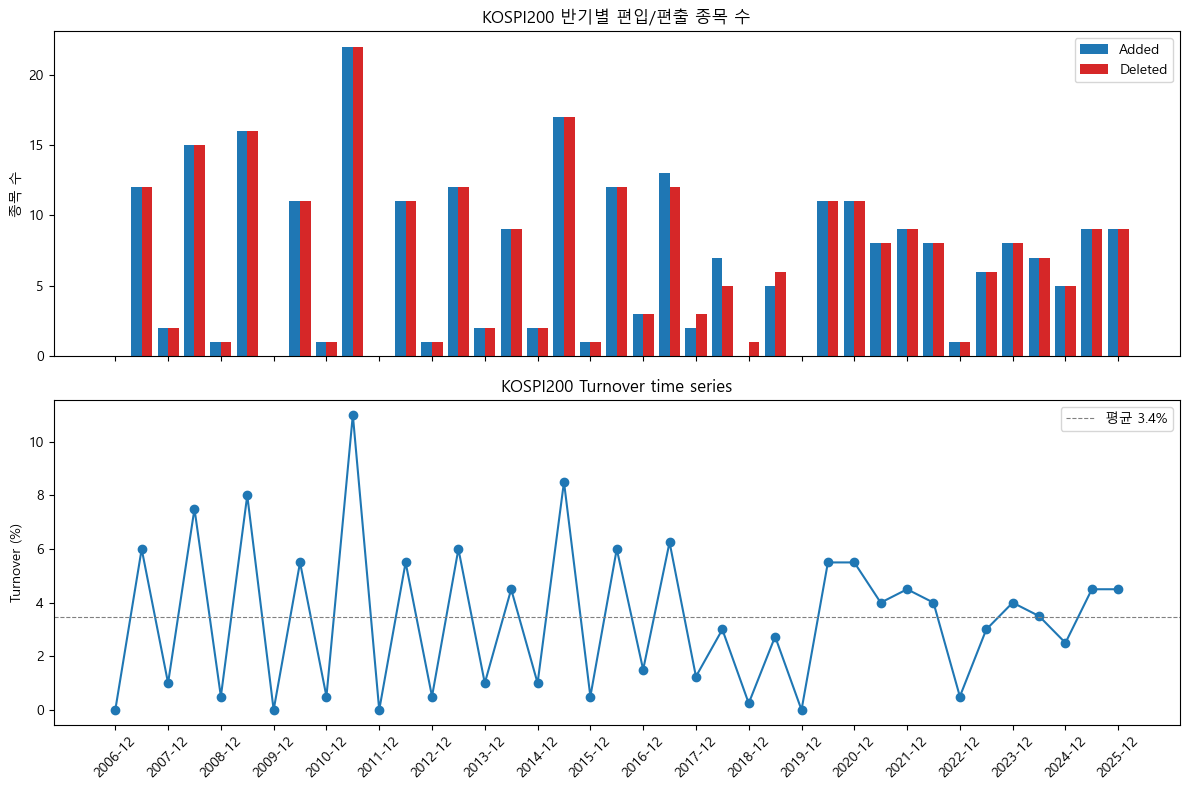

[FIGURE SAVED] outputs/figures/11_assignment2_turnover.png


,N_Added,N_Deleted,Added_Share,Deleted_Share,Net,Total_Changes
Industry,,,,,,
미분류(현재 KRX 목록에 없음),16,53,5.9%,19.7%,-37,69
기타금융,33,35,12.3%,13.0%,-2,68
화학,35,24,13.0%,8.9%,11,59
제약,22,25,8.2%,9.3%,-3,47
전기·전자,25,21,9.3%,7.8%,4,46
금속,16,17,5.9%,6.3%,-1,33
운송장비·부품,16,16,5.9%,5.9%,0,32
유통,16,9,5.9%,3.3%,7,25
음식료·담배,12,11,4.5%,4.1%,1,23


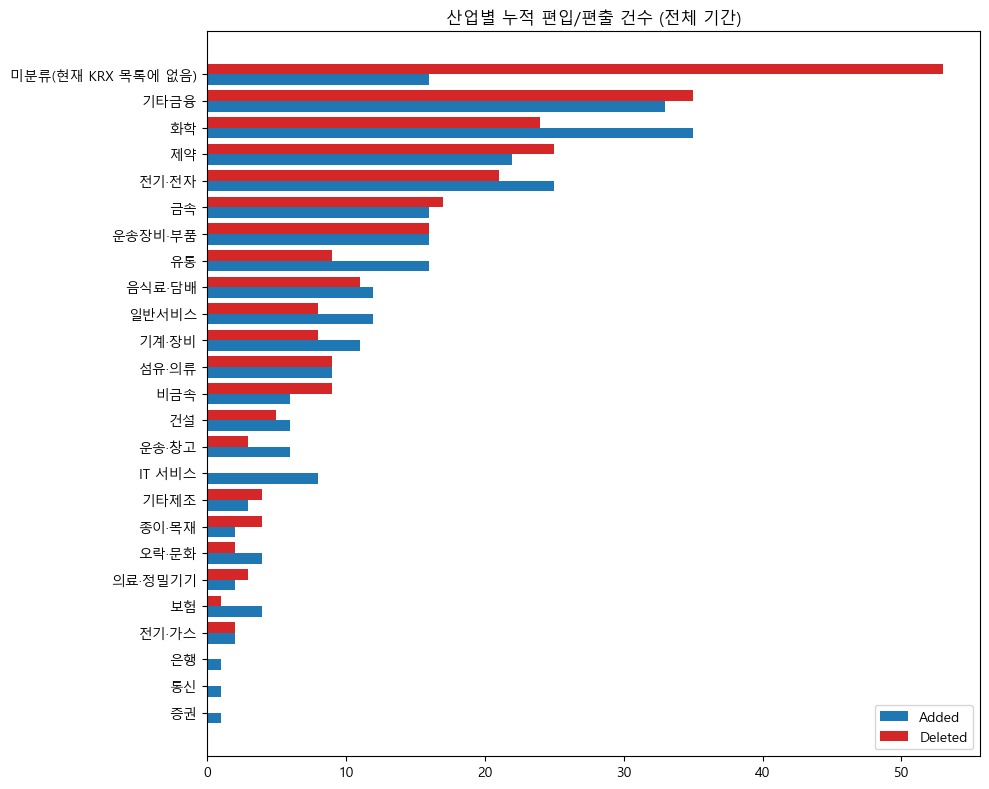

[FIGURE SAVED] outputs/figures/12_assignment2_industry_changes.png


,FirstDate,LastDate,N_Snapshots,N_Ever_Members,LongRun_SurvivalRate
0,2006-08-31,2025-12-30,40,414,44.0%


N_ever = 414 vs 현재 구성종목 200 → 과거에만 있었던 종목 214개 (51.7%)
평균 Turnover = 3.45%, 최대 = 11.00% (2011-08-31)
편입 최다 시점: 2011-08-31 | 편출 최다 시점: 2011-08-31


In [37]:
# ============================================================
# Assignment 2 — Student Work
# ============================================================
# Turnover convention: Turnover_t = (|Added_t| + |Deleted_t|) / (2 * |C_{t-1}|)
# 구성종목: data/kospi200_constituents/kospi200_YYYYMMDD.csv (반기별 40개 snapshot)
# 산업분류: KRX 업종분류현황(2025-12-30) → Assignment 1의 my_industry 재사용

# ------------------------------------------------------------
# 1) 모든 snapshot을 읽어 long-format history 구성
# ------------------------------------------------------------
snapshot_files = sorted(CONSTITUENT_DIR.glob("kospi200_*.csv"))
print("Snapshot files:", len(snapshot_files))

frames = []
for f in snapshot_files:
    asof = pd.to_datetime(f.stem.split("_")[1], format="%Y%m%d")
    tmp = read_csv_robust(f)
    frames.append(pd.DataFrame({
        "AsOfDate": asof,
        "Symbol": normalize_symbol(tmp["종목코드"]),
        "Name": tmp["종목명"].astype(str).str.strip(),
    }))

history = pd.concat(frames, ignore_index=True).dropna(subset=["Symbol"])
history = history.drop_duplicates(subset=["AsOfDate", "Symbol"])
history["AsOfDate"] = pd.to_datetime(history["AsOfDate"])
history.to_csv(DATA_DIR / "FDA_kospi200_constituents_history.csv", index=False, encoding="utf-8-sig")

# 종목코드 → 최신 종목명 (표시용)
latest_name = history.sort_values("AsOfDate").groupby("Symbol")["Name"].last()

# ------------------------------------------------------------
# 2) 기준일 확인, C_t 생성
# ------------------------------------------------------------
dates = sorted(history["AsOfDate"].unique())
constituents = {d: set(history.loc[history["AsOfDate"] == d, "Symbol"]) for d in dates}
print("기준일 수:", len(dates), "|", pd.Timestamp(dates[0]).date(), "~", pd.Timestamp(dates[-1]).date())

# Data integrity: KOSPI200은 200종목이 원칙 — 200개가 아닌 snapshot을 따로 확인한다.
# (코드 변경·중복 등이 있으면 같은 기업이 편출+편입으로 이중 집계될 수 있음)
snap_size = pd.Series({pd.Timestamp(d).date(): len(constituents[d]) for d in dates}, name="N")
irregular = snap_size[snap_size != 200]
print(f"\n구성종목 수가 200이 아닌 snapshot: {len(irregular)}개")
for d, n in irregular.items():
    snap = history[history["AsOfDate"] == pd.Timestamp(d)]
    dup_names = snap[snap["Name"].duplicated(keep=False)].sort_values("Name")
    print(f"  {d}: {n}개", "| 같은 종목명 중복:" if len(dup_names) else "| 종목명 중복 없음",
          ", ".join(f"{r.Name}({r.Symbol})" for r in dup_names.itertuples()))

# ------------------------------------------------------------
# 3) Stayed / Added / Deleted / Turnover (모든 연속 시점)
# ------------------------------------------------------------
records = []
added_events, deleted_events = [], []

for t in range(1, len(dates)):
    C_prev = constituents[dates[t - 1]]
    C_curr = constituents[dates[t]]
    res = compare_constituents(sorted(C_prev), sorted(C_curr))

    n_added, n_deleted = len(res["Added"]), len(res["Deleted"])
    records.append({
        "Date": pd.Timestamp(dates[t]),
        "N_Constituents": len(C_curr),
        "N_Stayed": len(res["Stayed"]),
        "N_Added": n_added,
        "N_Deleted": n_deleted,
        "Turnover": (n_added + n_deleted) / (2 * len(C_prev)),
    })
    added_events += [(pd.Timestamp(dates[t]), s) for s in res["Added"]]
    deleted_events += [(pd.Timestamp(dates[t]), s) for s in res["Deleted"]]

# Table 1
table1 = pd.DataFrame(records)
display(table1.style.format({"Turnover": "{:.2%}"}))
table1.to_csv(TABLE_DIR / "assignment2_table1_membership_change.csv", index=False, encoding="utf-8-sig")

# Table 1-b: 시점별 실제 편입(Added) / 편출(Deleted) 종목 목록
change_list = (
    pd.concat([
        pd.DataFrame(added_events, columns=["Date", "Symbol"]).assign(Change="Added"),
        pd.DataFrame(deleted_events, columns=["Date", "Symbol"]).assign(Change="Deleted"),
    ], ignore_index=True)
    .assign(Name=lambda d: d["Symbol"].map(latest_name))
    .sort_values(["Date", "Change", "Name"])
    .reset_index(drop=True)
)
change_list.to_csv(TABLE_DIR / "assignment2_added_deleted_list.csv", index=False, encoding="utf-8-sig")

change_by_date = (
    change_list.groupby([change_list["Date"].dt.date, "Change"])["Name"]
    .apply(lambda s: ", ".join(s))
    .unstack("Change")
    .reindex(columns=["Added", "Deleted"])
    .fillna("")
)
print("\n시점별 편입/편출 종목 (Stayed 종목 수는 위 Table 1의 N_Stayed)")
with pd.option_context("display.max_colwidth", None):
    display(change_by_date)

# ------------------------------------------------------------
# 4) Graph: Added/Deleted + Turnover
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

x = np.arange(len(table1))
axes[0].bar(x - 0.2, table1["N_Added"], width=0.4, label="Added")
axes[0].bar(x + 0.2, table1["N_Deleted"], width=0.4, label="Deleted", color="tab:red")
axes[0].set_ylabel("종목 수")
axes[0].set_title("KOSPI200 반기별 편입/편출 종목 수")
axes[0].legend()

axes[1].plot(x, table1["Turnover"] * 100, marker="o")
axes[1].axhline(table1["Turnover"].mean() * 100, color="gray", linestyle="--", linewidth=0.8,
                label=f"평균 {table1['Turnover'].mean():.1%}")
axes[1].set_ylabel("Turnover (%)")
axes[1].set_title("KOSPI200 Turnover time series")
axes[1].legend()

axes[1].set_xticks(x[::2])
axes[1].set_xticklabels(table1["Date"].dt.strftime("%Y-%m").iloc[::2], rotation=45)
fig.tight_layout()
save_figure(fig, "11_assignment2_turnover.png")
plt.show()

# ------------------------------------------------------------
# 5) Table 2: 전체 기간 누적 편입/편출 종목의 산업분포
#    산업분류는 2025-12-30 KRX 업종분류 기준이므로, 이미 상장폐지/합병된 종목은
#    매칭되지 않는다 → "미분류(현재 KRX 목록에 없음)"으로 별도 표기한다.
# ------------------------------------------------------------
industry_map = my_industry.set_index("Symbol")["Industry"]
UNMAPPED = "미분류(현재 KRX 목록에 없음)"


def industry_distribution(events, label):
    df = pd.DataFrame(events, columns=["Date", "Symbol"])
    df["Industry"] = df["Symbol"].map(industry_map).fillna(UNMAPPED)
    out = df.groupby("Industry").size().rename(label)
    return out, df


added_dist, added_df = industry_distribution(added_events, "N_Added")
deleted_dist, deleted_df = industry_distribution(deleted_events, "N_Deleted")

table2 = pd.concat([added_dist, deleted_dist], axis=1).fillna(0).astype(int)
table2["Added_Share"] = table2["N_Added"] / table2["N_Added"].sum()
table2["Deleted_Share"] = table2["N_Deleted"] / table2["N_Deleted"].sum()
table2["Net"] = table2["N_Added"] - table2["N_Deleted"]
table2["Total_Changes"] = table2["N_Added"] + table2["N_Deleted"]
table2 = table2.sort_values("Total_Changes", ascending=False)

display(table2.style.format({"Added_Share": "{:.1%}", "Deleted_Share": "{:.1%}"}))
table2.to_csv(TABLE_DIR / "assignment2_table2_industry_changes.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(10, 8))
t2 = table2.sort_values("Total_Changes")
ypos = np.arange(len(t2))
ax.barh(ypos - 0.2, t2["N_Added"], height=0.4, label="Added")
ax.barh(ypos + 0.2, t2["N_Deleted"], height=0.4, label="Deleted", color="tab:red")
ax.set_yticks(ypos)
ax.set_yticklabels(t2.index)
ax.set_title("산업별 누적 편입/편출 건수 (전체 기간)")
ax.legend()
fig.tight_layout()
save_figure(fig, "12_assignment2_industry_changes.png")
plt.show()

# ------------------------------------------------------------
# 6) Summary: SurvivalRate_{1,T}, N_ever
# ------------------------------------------------------------
C_first, C_last = constituents[dates[0]], constituents[dates[-1]]
n_ever = len(set().union(*constituents.values()))
survival = len(C_first & C_last) / len(C_first)

summary = pd.DataFrame([{
    "FirstDate": pd.Timestamp(dates[0]).date(),
    "LastDate": pd.Timestamp(dates[-1]).date(),
    "N_Snapshots": len(dates),
    "N_Ever_Members": n_ever,
    "LongRun_SurvivalRate": survival,
}])
display(summary.style.format({"LongRun_SurvivalRate": "{:.1%}"}))
summary.to_csv(TABLE_DIR / "assignment2_summary.csv", index=False, encoding="utf-8-sig")

print(f"N_ever = {n_ever} vs 현재 구성종목 {len(C_last)} → 과거에만 있었던 종목 {n_ever - len(C_last)}개 "
      f"({1 - len(C_last) / n_ever:.1%})")
print(f"평균 Turnover = {table1['Turnover'].mean():.2%}, 최대 = {table1['Turnover'].max():.2%} "
      f"({table1.loc[table1['Turnover'].idxmax(), 'Date'].date()})")
print("편입 최다 시점:", table1.loc[table1["N_Added"].idxmax(), "Date"].date(),
      "| 편출 최다 시점:", table1.loc[table1["N_Deleted"].idxmax(), "Date"].date())


### Assignment 2 Interpretation

분석 결과를 3~5문장으로 해석하시오.

2006-08-31부터 2025-12-30까지 40개 반기 snapshot에서 평균 turnover는 3.45%이지만 시간에 따라 일정하지 않으며, 변경은 주로 8월 snapshot(6월 정기변경 반영)에 몰리고 12월 snapshot은 2019년까지 0~1.5% 수준이었다가 2020년 12월 이후에는 2022년 12월(0.5%)을 제외하면 2.5~5.5%로 높아졌다(turnover convention: $(|Added_t|+|Deleted_t|)/(2|C_{t-1}|)$). 편입·편출이 가장 많았던 시점은 2011-08-31(각 22종목, turnover 11.0%)이고 2015-08(8.5%), 2009-08(8.0%), 2008-08(7.5%)도 높았으며, 산업별로는 기타금융(편입 33/편출 35), 화학(35/24), 제약(22/25), 전기·전자(25/21)에서 변동이 많았다. 특히 전체 편출 269건 중 53건(19.7%)은 현재 KRX 업종목록에 존재하지 않는(상장폐지·합병·코드변경 등) 종목으로, 편입 쪽 비율(5.9%)보다 훨씬 높아 편출 종목 상당수가 시장에서 아예 사라졌음을 보여준다. 2006-08 구성종목 중 2025-12까지 남아 있는 비율은 44.0%에 불과하고, 전체 기간 한 번이라도 KOSPI200에 포함된 종목은 414개로 현재 구성종목 200개의 두 배가 넘어 214개(51.7%)는 현재 universe에 없다. 따라서 현재 구성종목만으로 과거를 분석하면 부진·부실로 편출되거나 상장폐지된 기업은 체계적으로 빠지고 이후 성장해 편입된 '승자'만 남게 되어, 과거 수익률과 기술적 전략의 성과는 과대평가되고 위험은 과소평가되므로 백테스트는 반드시 point-in-time universe로 수행해야 한다.

In [38]:
# ============================================================
# Assignment 2 — 결과 요약
# ============================================================
# Turnover convention: (|Added_t| + |Deleted_t|) / (2 * |C_{t-1}|)
a2_max_row = table1.loc[table1["Turnover"].idxmax()]

print("[RESULT] A2_FIRST_DATE =", pd.Timestamp(dates[0]).date())
print("[RESULT] A2_LAST_DATE =", pd.Timestamp(dates[-1]).date())
print("[RESULT] A2_N_SNAPSHOTS =", len(dates))

print("[RESULT] A2_N_EVER_MEMBERS =", n_ever)
print("[RESULT] A2_LONGRUN_SURVIVAL_RATE =", float(survival))

print("[RESULT] A2_TOTAL_ADDED =", int(table1["N_Added"].sum()))
print("[RESULT] A2_TOTAL_DELETED =", int(table1["N_Deleted"].sum()))

print("[RESULT] A2_MEAN_TURNOVER =", float(table1["Turnover"].mean()))
print("[RESULT] A2_MAX_TURNOVER =", float(a2_max_row["Turnover"]))
print("[RESULT] A2_MAX_TURNOVER_DATE =", a2_max_row["Date"].date())


[RESULT] A2_FIRST_DATE = 2006-08-31
[RESULT] A2_LAST_DATE = 2025-12-30
[RESULT] A2_N_SNAPSHOTS = 40
[RESULT] A2_N_EVER_MEMBERS = 414
[RESULT] A2_LONGRUN_SURVIVAL_RATE = 0.44
[RESULT] A2_TOTAL_ADDED = 269
[RESULT] A2_TOTAL_DELETED = 269
[RESULT] A2_MEAN_TURNOVER = 0.03448144211665712
[RESULT] A2_MAX_TURNOVER = 0.11
[RESULT] A2_MAX_TURNOVER_DATE = 2011-08-31


# 데이터 출처 기록

이번 과제에서 사용한 데이터의 출처를 아래 표에 직접 채운다. 어떤
자료를 사용했는지 명시하는 것은 채점에서 중요하게 본다.

| 데이터 | 출처 | 기준일/기간 |
|---|---|---|
| KOSPI200 구성종목 | KRX 정보데이터시스템 > 지수 > 지수구성종목 (http://data.krx.co.kr) — `data/kospi200_constituents/kospi200_20251230.csv` | 2025-12-30 |
| 산업분류 | KRX 정보데이터시스템 > 업종분류현황, KRX 업종명 (http://data.krx.co.kr) — 원본 `data/data_1628_20261003.csv` → 정리본 `data/FDA_kospi200_industry.csv` | 조회일자 2025-12-30 (다운로드 2026-10-03) |
| 주가자료 | 개별종목: Yahoo Finance (https://finance.yahoo.com, `yfinance`, `period="max"`, Adj Close 포함) / KOSPI200 지수: FinanceDataReader (https://github.com/FinanceData/FinanceDataReader, `KS200`). Notebook에서 직접 다운로드하므로 가격 파일은 별도 제출하지 않음. Yahoo 다운로드 실패 종목은 Run All 후 §10 출력 및 `outputs/tables/yahoo_failed_tickers.csv`에 기록됨 | 개별종목: 종목별 최초 관측일(가장 이른 2000-01-04) ~ 2025-12-30 / 지수: 2010-01-04 ~ 2025-12-30 |
| Historical 구성종목 | KRX 정보데이터시스템 > 지수 > 지수구성종목, KOSPI200 반기 snapshot 40개 (http://data.krx.co.kr) — `data/kospi200_constituents/kospi200_YYYYMMDD.csv` → 정리본 `data/FDA_kospi200_constituents_history.csv` | 2006-08-31 ~ 2025-12-30 (매년 8월 말·12월 말) |

출처 예시: Yahoo Finance, FinanceDataReader, KRX, DataGuide, 기타
신뢰할 수 있는 데이터 source. 가능하면 URL 또는 데이터서비스명을
함께 적는다.


# 과제 제출 방법

1. 필요한 데이터를 직접 찾는다.
2. `data/` 폴더에 저장한다.
3. Notebook 분석을 완료한다.
4. Restart Kernel → Run All
5. Save
6. Notebook과 실제 사용한 데이터 파일을 하나의 폴더에 넣는다.
7. 전체 폴더를 ZIP 하나로 압축해 제출한다.

### 폴더 구조 (예시)

```text
FDA_week02_학번_이름/
│
├─ FDA_week02_lab_assignment_학번_이름.ipynb
│
└─ data/
   ├─ 구성종목 파일
   ├─ 산업분류 파일
   ├─ historical 구성종목 파일
   └─ 기타 실제 사용 데이터
```

### ZIP 파일명

```text
FDA_week02_학번_이름.zip
```

예: `FDA_week02_20261234_홍길동.zip`

### Notebook 파일명

```text
FDA_week02_lab_assignment_학번_이름.ipynb
```

예: `FDA_week02_lab_assignment_20261234_홍길동.ipynb`

# 제출 전 Checklist

- [ ] 학번과 이름을 파일명에 넣었다.
- [ ] Assignment 1을 완료했다.
- [ ] Assignment 2를 완료했다.
- [ ] 데이터 출처와 기준일/기간을 기록했다.
- [ ] Assignment 1 마지막에 [RESULT] 출력 셀을 추가했다.
- [ ] Assignment 2 마지막에 [RESULT] 출력 셀을 추가했다.
- [ ] Restart Kernel → Run All을 실행했다.
- [ ] 코드 실행 결과와 그래프가 Notebook에 저장되어 있다.
- [ ] 실제 사용한 데이터 파일을 `data/` 폴더에 넣었다.
- [ ] 전체 폴더를 ZIP 파일 하나로 만들었다.
- [ ] ZIP 파일명이 `FDA_week02_학번_이름.zip` 형식인지 확인했다.


# Lab 1 핵심 정리

1. **Universe**: 2025-12-30 기준 KOSPI200 구성종목 200개.
2. **Observation Grain**: $\text{Date} \times \text{Symbol}$.
3. **Data Availability**: 종목마다 관측 가능한 history가 다르다.
4. **Unbalanced Panel**: 모든 종목이 동일한 날짜에 존재할 필요는
   없다.
5. **Missing Data**: 상장 전 / 거래정지 / 휴장일은 서로 다른
   경제적 원인을 갖는다.
6. **Extreme Returns**: 삭제 대상이 아니라 조사 대상이다.
7. **6-series EDA**: 개별 EDA는 각자의 full history, 비교/상관관계
   분석은 공통 구간만 사용한다.
8. **Survivorship Bias**: `period="max"`로 가격 history를 길게
   받는 것과 universe가 point-in-time으로 정확한 것은 다른 문제다.
9. **Lab vs Assignment**: Lab은 vendor 데이터를 직접 받아보는
   경험이고, Assignment는 여러분이 스스로 자료를 찾아 근거를 남기는
   연습이다.
10. **다음 단계**: Lab 2에서 Moving Average, EMA, Momentum, RSI 등
    기술적 지표와 `TechnicalStart_i`를 계산한다.